# Synthetic knowledge graph QA: exploratory data analysis

This notebook inspects the **existing** fictional academic graph and its QA splits. It performs no generation, training, or reward computation. All answers and paths shown here are private inspection metadata.

The analysis separates stored triples from permitted navigation operations; question rows from unique query instances; and intended program length from shortest graph distance and reference execution cost. Conclusions are computed from the loaded data.

**Contents**
1. [Configuration and read-only loading](#configuration)
2. [Dataset overview and schema checks](#overview)
3. [Graph structure, connectivity, and institutional coverage](#structure)
4. [Question programs and answer/start distributions](#questions)
5. [Language diversity and near duplicates](#language)
6. [Navigation difficulty and metadata verification](#difficulty)
7. [Split overlap and leakage](#leakage)
8. [Fifteen reproducible question inspections](#examples)
9. [Graph inspection in Protégé](#protege)
10. [Quality assessment](#quality)
11. [Observed findings and recommendations](#summary)
12. [Input integrity and execution checks](#integrity)

Run all cells with Python 3.11+. Local dependencies are listed in `requirements-eda.txt`; Kaggle normally provides the analysis libraries. Set the paths below when using a mounted Kaggle dataset. Outputs go to a separate writable directory.

<a id="configuration"></a>
## 1. Configuration and read-only loading

Defaults detect a local repository from the current directory or its parents. On Kaggle, upload the repository (including `src/kg_rlvr`) and saved data, then set `PROJECT_ROOT_OVERRIDE` and, if needed, `DATA_DIR_OVERRIDE`. No network calls or package installation occur in this notebook.

`OUTPUT_BASE` is writable and outside the input dataset. Statistical charts and reports go under `artifacts/eda/` locally; all Kaggle outputs default to `/kaggle/working/kg_rlvr_eda/`. Open `data/graph/graph.ttl` in Protégé to inspect the graph and ontology.

In [1]:
from pathlib import Path
import os
import sys
import tempfile

# Edit these three paths for a different local layout or a mounted Kaggle dataset.
PROJECT_ROOT_OVERRIDE = None  # e.g. Path("/kaggle/input/my-kg-project/graph_rlvr")
DATA_DIR_OVERRIDE = None     # e.g. Path("/kaggle/input/my-kg-data/data")
OUTPUT_BASE_OVERRIDE = None  # e.g. Path("/kaggle/working/kg_rlvr_eda")
SEED = 41
SAMPLES_PER_HOP = 5
RUN_FULL_VALIDATION = True
NEAR_DUPLICATE_JACCARD = 0.82  # lexical review heuristic, never a validity rule
NEAR_DUPLICATE_CANDIDATES_PER_ROW = 6

def find_project():
    explicit = PROJECT_ROOT_OVERRIDE or os.environ.get("KG_RLVR_PROJECT_ROOT")
    if explicit:
        return Path(explicit).expanduser().resolve()
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "src/kg_rlvr/graph_index.py").is_file():
            return candidate
    candidates = sorted(Path("/kaggle/input").glob("*/src/kg_rlvr/graph_index.py"))
    candidates += sorted(Path("/kaggle/input").glob("*/*/src/kg_rlvr/graph_index.py"))
    if len(candidates) == 1:
        return candidates[0].parents[2]
    raise FileNotFoundError("Set PROJECT_ROOT_OVERRIDE to the uploaded repository containing src/kg_rlvr.")

PROJECT_ROOT = find_project()
DATA_DIR = Path(DATA_DIR_OVERRIDE or os.environ.get("KG_RLVR_DATA_DIR", PROJECT_ROOT / "data")).expanduser().resolve()
default_output = Path("/kaggle/working/kg_rlvr_eda") if Path("/kaggle/working").exists() else PROJECT_ROOT / "artifacts/eda"
OUTPUT_BASE = Path(OUTPUT_BASE_OVERRIDE or os.environ.get("KG_RLVR_EDA_OUTPUT_DIR", default_output)).expanduser().resolve()
sys.path.insert(0, str(PROJECT_ROOT / "src"))
# Keep matplotlib/font caches away from read-only home or Kaggle input directories.
cache_root = Path(tempfile.gettempdir()) / "kg_rlvr_eda_cache"
cache_root.mkdir(exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(cache_root / "matplotlib"))
os.environ.setdefault("XDG_CACHE_HOME", str(cache_root))
print(f"Project: {PROJECT_ROOT}\nDataset: {DATA_DIR}\nOutputs: {OUTPUT_BASE}\nSeed: {SEED}")

Project: /Users/alirezaak/Documents/research/graph_rlvr
Dataset: /Users/alirezaak/Documents/research/graph_rlvr/data
Outputs: /Users/alirezaak/Documents/research/graph_rlvr/artifacts/eda
Seed: 41


In [2]:
import hashlib
import html
import json
import random
import textwrap
from collections import Counter
from itertools import combinations
import importlib.metadata

import warnings
with warnings.catch_warnings(record=True) as pandas_notices:
    warnings.simplefilter("always", UserWarning)
    import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from IPython.display import HTML, Markdown, display
from kg_rlvr.eda import (
    fingerprint, graph_views, lexical_summary,
    load_data, navigation_audit, near_duplicate_screen, output_directory,
    quality_assessment, question_frame, question_html, schema_audit,
    split_overlaps, stratified_samples,
)
from kg_rlvr.graph_index import execute

get_ipython().run_line_magic("matplotlib", "inline")
plt.rcParams.update({
    "figure.figsize": (11, 4.4), "figure.dpi": 110, "savefig.dpi": 130,
    "figure.constrained_layout.use": True, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.18,
    "axes.axisbelow": True, "font.size": 10, "axes.titlesize": 12,
    "axes.labelsize": 10, "legend.frameon": False, "font.family": "DejaVu Sans",
})
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.max_rows", 35)
COLORS = {1: "#9467bd", 2: "#2864a6", 3: "#dd8733", 4: "#259485"}
FIGURE_DIR = output_directory(OUTPUT_BASE / "figures", DATA_DIR)
REPORT_DIR = output_directory(OUTPUT_BASE / "reports", DATA_DIR)
CHARTS = []
def finish(fig, name):
    path = FIGURE_DIR / f"{name}.png"
    fig.savefig(path, bbox_inches="tight", facecolor="white")
    CHARTS.append(path)
    plt.show()
    plt.close(fig)

INPUT_HASHES = fingerprint(DATA_DIR)
graph, records, config = load_data(DATA_DIR)
qa = question_frame(graph, records)
record_by_id = {q["id"]: q for q in records}
split_order = [s for s in ["train", "validation", "test"] if s in set(qa.split)]
split_order += sorted(set(qa.split) - set(split_order))
versions = {p: importlib.metadata.version(p) for p in ["rdflib", "pandas", "networkx", "matplotlib", "nbformat", "nbclient"]}
display(pd.Series(versions, name="installed version").to_frame())
if pandas_notices:
    display(pd.DataFrame({"dependency notice": [str(notice.message) for notice in pandas_notices]}))
print(f"Loaded {len(records):,} question rows; snapshotted {len(INPUT_HASHES)} source files.")

,installed version
rdflib,7.6.0
pandas,2.3.2
networkx,3.1
matplotlib,3.7.2
nbformat,5.9.2
nbclient,0.5.13


,dependency notice
0,Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).


Loaded 3,734 question rows; snapshotted 10 source files.


<a id="overview"></a>
## 2. Dataset overview and schema checks

A **composition** is an ordered tuple of relation-operation IDs, including permitted `inv:` traversals. A **query instance** combines the start, program, and complete answer set; paraphrases count as separate question rows but belong to one instance. We compute these keys from the records rather than trusting their saved hashes.

In [3]:
summary = pd.Series({
    "Entities": len(graph.entities), "Stored triples": len(graph.triples),
    "Ontology relations": len(graph.relations),
    "Entity types": len({e["type"] for e in graph.entities.values()}),
    "Questions": len(qa), "Unique query instances": qa.instance_key.nunique(),
    "Unique relation compositions": qa.composition.nunique(),
    "Unique starting entities": qa.start_entity.nunique(),
    "Unique answer entities": len({a for answers in qa.answer_ids for a in answers}),
}, name="count").to_frame()
display(summary)
split_hops = pd.crosstab(qa.split, qa.hop_count).reindex(index=split_order, columns=[1, 2, 3, 4], fill_value=0)
display(split_hops.assign(total=split_hops.sum(axis=1)).rename_axis(columns="intended program hops"))
schema = schema_audit(graph, records)
display(schema)
if schema.loc[schema.importance == "required", "count"].sum():
    display(Markdown("**Required schema/reference issues were found. Inspect the table before interpreting downstream results.**"))
print("Optional metadata absent in", int((schema.query("importance == 'optional'")["count"] > 0).sum()), "field(s).")

,count
Entities,2000
Stored triples,5000
Ontology relations,16
Entity types,8
Questions,3734
Unique query instances,1870
Unique relation compositions,46
Unique starting entities,1091
Unique answer entities,834


intended program hops,1,2,3,4,total
split,,,,,
train,667,667,667,666,2667
validation,100,100,100,100,400
test,167,167,167,166,667


,check,count,importance,explanation
0,Missing answer_ids,0,required,Missing optional metadata is reported and recomputed where possible.
1,Missing answer_path_counts,0,optional,Missing optional metadata is reported and recomputed where possible.
2,Missing difficulty,0,optional,Missing optional metadata is reported and recomputed where possible.
3,Missing gold_entity_paths,0,optional,Missing optional metadata is reported and recomputed where possible.
4,Missing hop_count,0,required,Missing optional metadata is reported and recomputed where possible.
5,Missing id,0,required,Missing optional metadata is reported and recomputed where possible.
6,Missing program_id,0,optional,Missing optional metadata is reported and recomputed where possible.
7,Missing query_instance_id,0,optional,Missing optional metadata is reported and recomputed where possible.
8,Missing question,0,required,Missing optional metadata is reported and recomputed where possible.
9,Missing relation_path,0,required,Missing optional metadata is reported and recomputed where possible.


Optional metadata absent in 0 field(s).


<a id="structure"></a>
## 3. Knowledge graph structure

Three graph views answer different questions:

- `stored` is a directed **MultiDiGraph** containing every stored triple, including explicit reciprocal triples for symmetric relations.
- `simple` collapses multiple relations between the same ordered pair. Its density and reciprocity measure endpoint connectivity, not relation semantics.
- `navigation` adds only the inverses permitted by the ontology. Its edges measure operations an agent can actually traverse, collapsed by endpoint pair.

All nodes, including isolates, are explicitly added. Component analysis is linear in nodes and edges. No all-pairs shortest paths or betweenness centrality are computed.

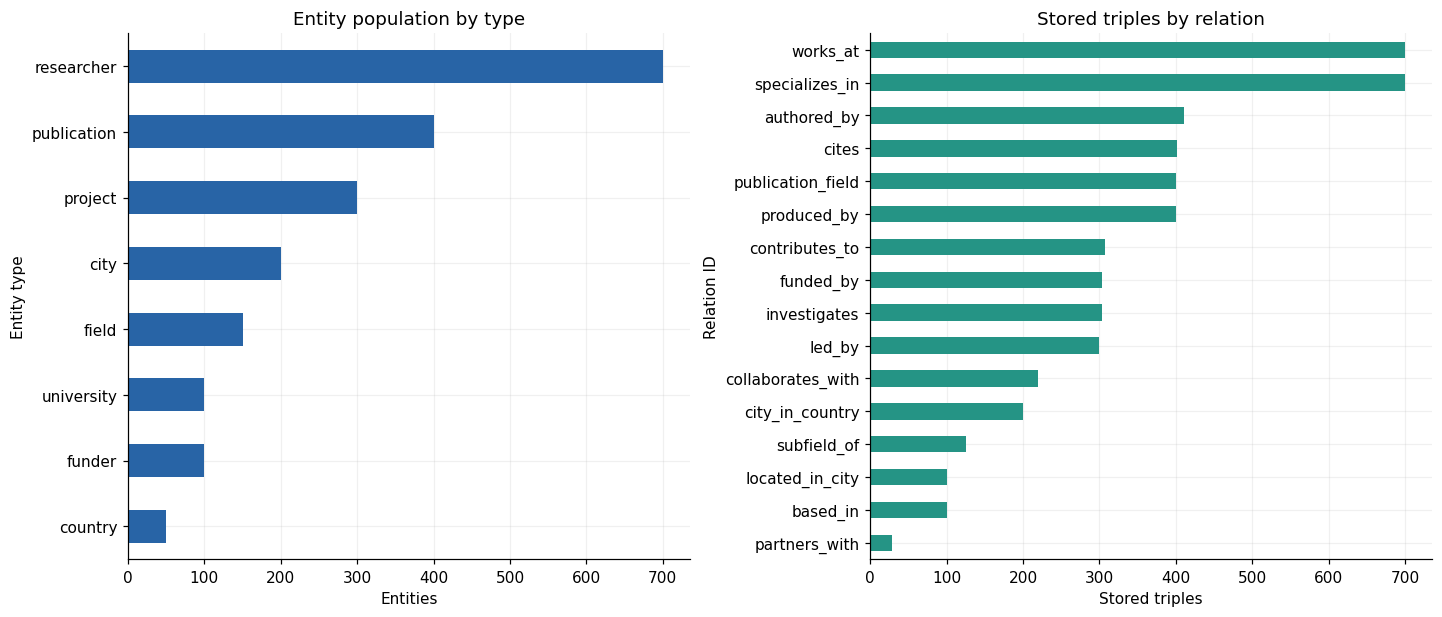

,entity_count,mean_total_degree
type,,
city,200,2.00
country,50,4.00
field,150,11.02
funder,100,4.04
project,300,5.38
publication,400,5.04
researcher,700,4.08
university,100,8.56


In [4]:
stored, simple, navigation, entities, triples, operation_neighbors = graph_views(graph)
entity_counts = entities.type.value_counts().sort_values()
relation_counts = triples.relation.value_counts().sort_values()
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
entity_counts.plot.barh(ax=axes[0], color="#2864a6")
axes[0].set(title="Entity population by type", xlabel="Entities", ylabel="Entity type")
relation_counts.plot.barh(ax=axes[1], color="#259485")
axes[1].set(title="Stored triples by relation", xlabel="Stored triples", ylabel="Relation ID")
finish(fig, "01_entity_relation_counts")
display(pd.DataFrame({"entity_count": entities.groupby("type").size(), "mean_total_degree": entities.groupby("type").total_degree.mean()}).round(2))

,observed
Stored directed multiedges,5000.000000
Distinct stored ordered endpoint pairs,5000.000000
Simple directed density,0.001251
Stored endpoint-pair reciprocity,0.169600
Weak components,1.000000
Largest weak component,2000.000000
Strong components (stored directions),1576.000000
Largest stored strong component,153.000000
Strong components (permitted navigation),1.000000
Largest navigation strong component,2000.000000


,in_degree,out_degree,total_degree,unique_neighbors,navigation_degree
mean,2.5,2.5,5.0,4.58,4.58
median,2.0,3.0,5.0,4.00,4.00
max,18.0,6.0,19.0,19.00,19.00


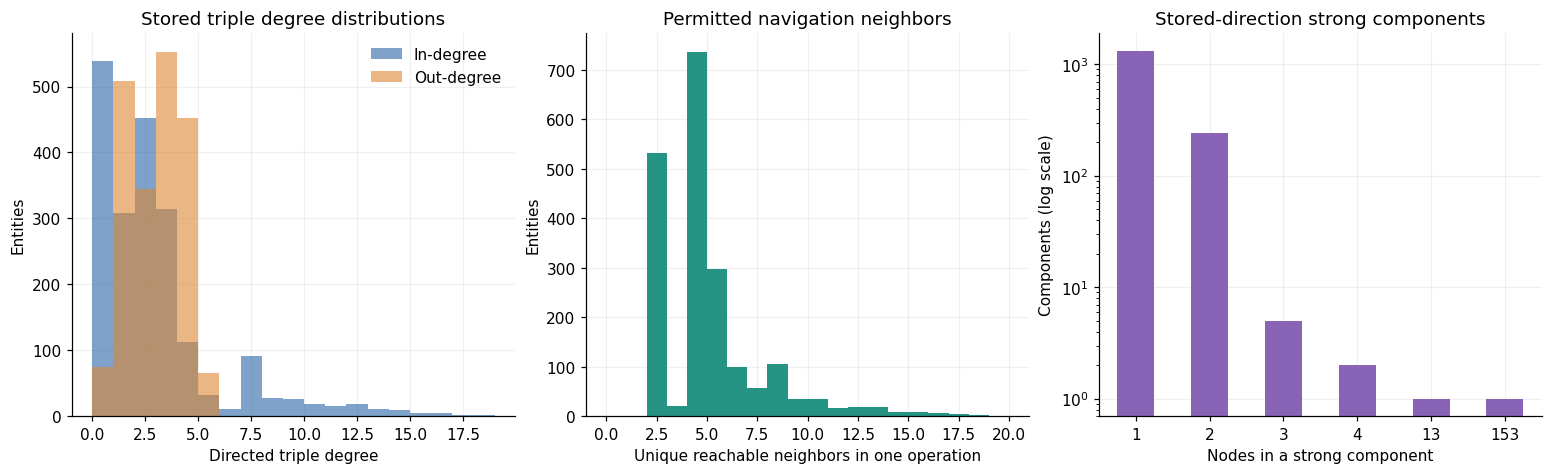

,entity_id,name,type,in_degree,out_degree,navigation_degree
1999,field_000029,Discipline Qornuvorv 0030,field,18,1,19
1997,field_000052,Discipline Vexvexpha 0053,field,17,1,18
1998,field_000003,Discipline Qorkyrzae 0004,field,18,0,18
1993,field_000085,Discipline Thaexelkyr 0086,field,16,1,17
1994,field_000094,Discipline Nuvnuvith 0095,field,16,1,17
1995,field_000096,Discipline Vexvexnuv 0097,field,16,1,17
1996,field_000023,Discipline Zhathaelym 0024,field,17,0,17
1987,field_000027,Discipline Phaithzae 0028,field,15,1,16
1988,field_000037,Discipline Nuvithzae 0038,field,15,1,16
1989,field_000077,Discipline Zaethaexel 0078,field,15,1,16


,weak_component_size
0,2000


In [5]:
weak_sizes = sorted(map(len, nx.weakly_connected_components(simple)), reverse=True)
strong_sizes = sorted(map(len, nx.strongly_connected_components(simple)), reverse=True)
nav_strong_sizes = sorted(map(len, nx.strongly_connected_components(navigation)), reverse=True)
isolates = list(nx.isolates(simple))
graph_metrics = pd.Series({
    "Stored directed multiedges": stored.number_of_edges(),
    "Distinct stored ordered endpoint pairs": simple.number_of_edges(),
    "Simple directed density": nx.density(simple),
    "Stored endpoint-pair reciprocity": nx.reciprocity(simple) or 0,
    "Weak components": len(weak_sizes), "Largest weak component": max(weak_sizes),
    "Strong components (stored directions)": len(strong_sizes),
    "Largest stored strong component": max(strong_sizes),
    "Strong components (permitted navigation)": len(nav_strong_sizes),
    "Largest navigation strong component": max(nav_strong_sizes), "Isolated nodes": len(isolates),
}, name="observed").to_frame()
display(graph_metrics)
display(entities[["in_degree", "out_degree", "total_degree", "unique_neighbors", "navigation_degree"]].agg(["mean", "median", "max"]).round(2))
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for column, label, color in [("in_degree", "In-degree", "#2864a6"), ("out_degree", "Out-degree", "#dd8733")]:
    axes[0].hist(entities[column], bins=range(int(entities[["in_degree", "out_degree"]].max().max()) + 2), alpha=.6, label=label, color=color)
axes[0].set(title="Stored triple degree distributions", xlabel="Directed triple degree", ylabel="Entities")
axes[0].legend()
axes[1].hist(entities.navigation_degree, bins=range(int(entities.navigation_degree.max()) + 2), color="#259485")
axes[1].set(title="Permitted navigation neighbors", xlabel="Unique reachable neighbors in one operation", ylabel="Entities")
pd.Series(strong_sizes).value_counts().sort_index().plot.bar(ax=axes[2], color="#8963b6", rot=0)
axes[2].set_yscale("log")
axes[2].set(title="Stored-direction strong components", xlabel="Nodes in a strong component", ylabel="Components (log scale)")
finish(fig, "02_degree_and_components")
display(entities.nlargest(12, "total_degree")[["entity_id", "name", "type", "in_degree", "out_degree", "navigation_degree"]])
display(pd.DataFrame({"weak_component_size": weak_sizes}))

,relation,triples,same_relation_reverse_fraction,declared_symmetric
0,authored_by,411,0.0,False
1,based_in,100,0.0,False
2,cites,402,0.0,False
3,city_in_country,200,0.0,False
4,collaborates_with,220,1.0,True
5,contributes_to,307,0.0,False
6,funded_by,304,0.0,False
7,investigates,303,0.0,False
8,led_by,300,0.0,False
9,located_in_city,100,0.0,False


,entities_with_operation,mean_nonzero_fanout,median_nonzero_fanout,max_fanout
operation,,,,
authored_by,400,1.03,1.0,2
based_in,100,1.00,1.0,1
cites,399,1.01,1.0,2
city_in_country,200,1.00,1.0,1
collaborates_with,120,1.83,2.0,3
contributes_to,304,1.01,1.0,2
funded_by,300,1.01,1.0,2
inv:authored_by,306,1.34,1.0,3
inv:based_in,100,1.00,1.0,1


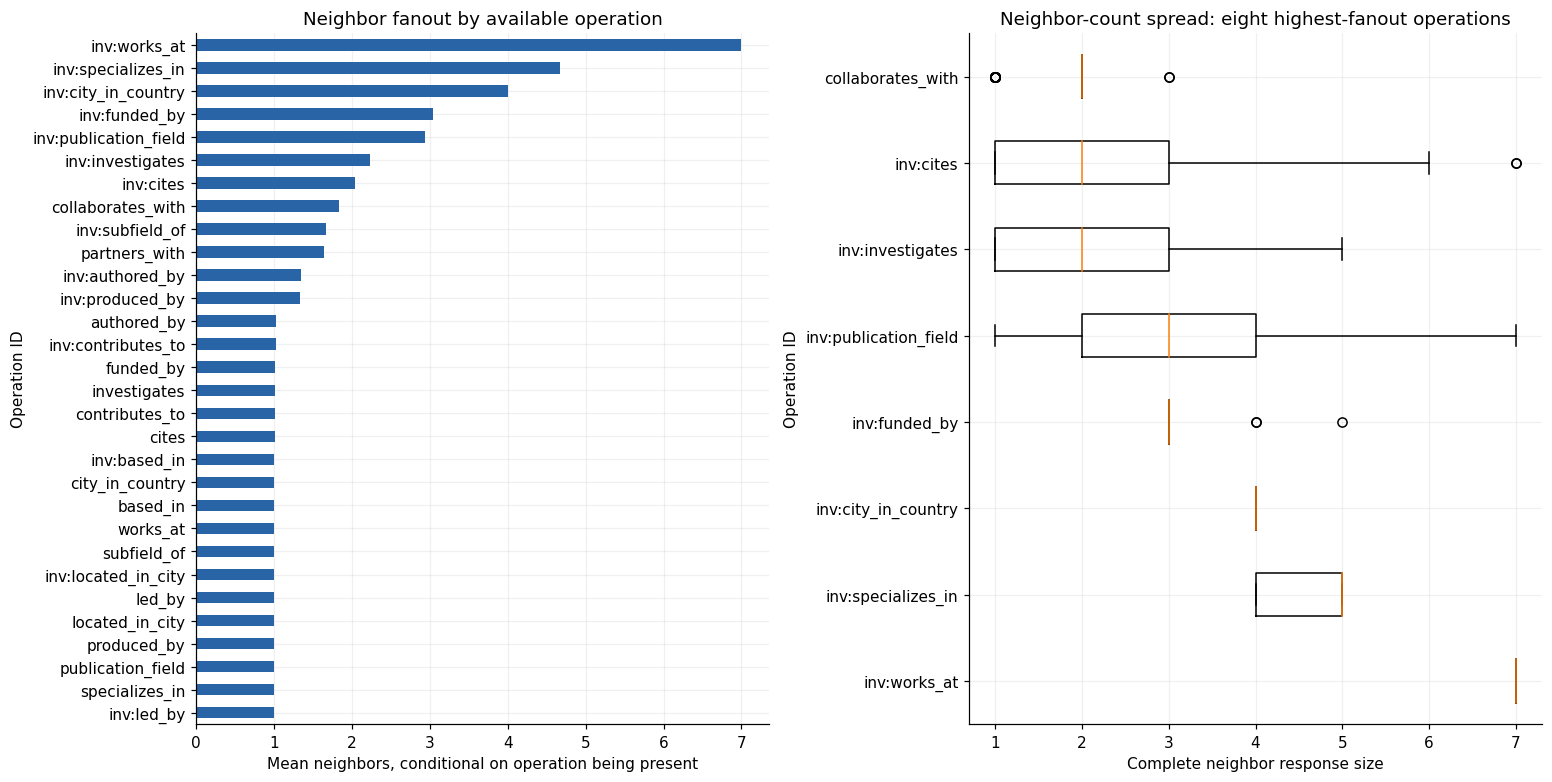

In [6]:
edge_set = set(graph.triples)
reciprocity_by_relation = pd.DataFrame([
    {"relation": relation, "triples": len(part),
     "same_relation_reverse_fraction": sum((t, relation, h) in edge_set for h, _, t in part.itertuples(index=False, name=None)) / len(part),
     "declared_symmetric": graph.relations[relation]["symmetric"]}
    for relation, part in triples.groupby("relation")
])
display(reciprocity_by_relation)
branch_summary = operation_neighbors.groupby("operation").neighbor_count.agg(["count", "mean", "median", "max"])
branch_summary.columns = ["entities_with_operation", "mean_nonzero_fanout", "median_nonzero_fanout", "max_fanout"]
display(branch_summary.round(2))
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
branch_summary.mean_nonzero_fanout.sort_values().plot.barh(ax=axes[0], color="#2864a6")
axes[0].set(title="Neighbor fanout by available operation", xlabel="Mean neighbors, conditional on operation being present", ylabel="Operation ID")
most_branching = branch_summary.nlargest(8, "mean_nonzero_fanout").index.tolist()
axes[1].boxplot([operation_neighbors.loc[operation_neighbors.operation == op, "neighbor_count"] for op in most_branching], vert=False, labels=most_branching, showfliers=True)
axes[1].set(title="Neighbor-count spread: eight highest-fanout operations", xlabel="Complete neighbor response size", ylabel="Operation ID")
finish(fig, "03_relation_branching")

### Institutional, geographic, and field coverage

The next tables use the graph's functional relations to aggregate researcher employment and location, plus primary specialties and investigated project fields. Country counts follow the university's city; they are not researcher citizenship. Project counts per field are edge incidences, so a multi-field project can contribute to multiple fields. The full zero-inclusive coverage table prevents unused countries or fields from disappearing from the analysis.

,count,mean,std,min,25%,50%,75%,max,zero_count_groups
Researchers / university,100.0,7.00,0.00,7.0,7.00,7.0,7.0,7.0,0
Researchers / employer country,50.0,14.00,6.32,0.0,8.75,14.0,14.0,28.0,2
Researchers / primary field,150.0,4.67,0.47,4.0,4.00,5.0,5.0,5.0,0
Project-field incidences / field,150.0,2.02,1.16,0.0,1.00,2.0,3.0,5.0,14


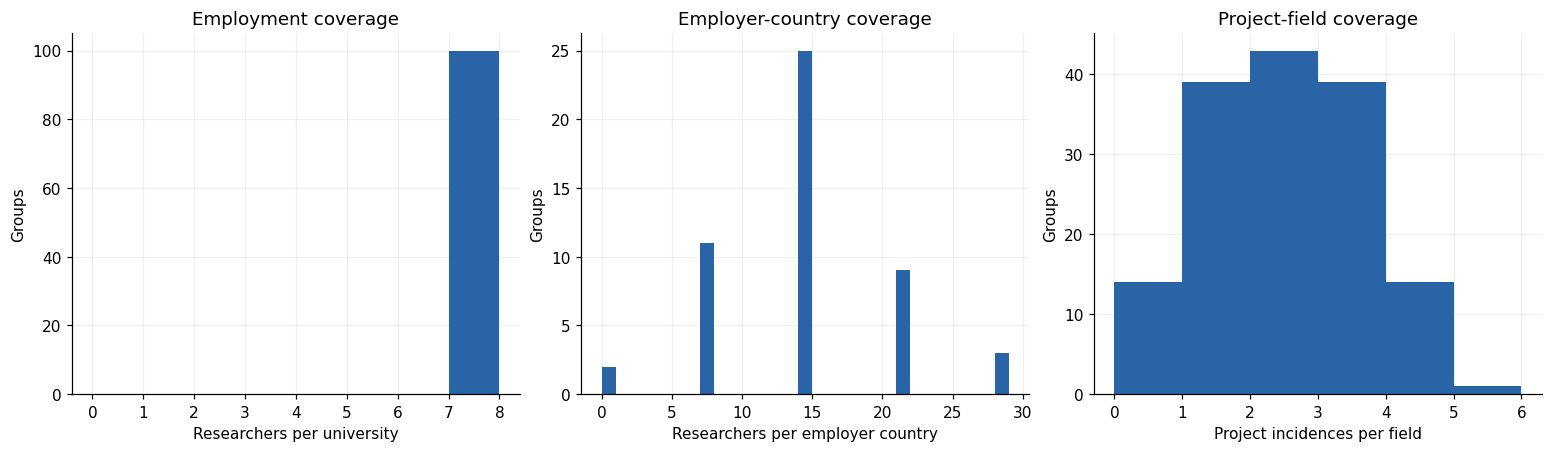

The stored graph has **1 weak component(s)** and **0 isolates**. Permitted navigation has **1 strong component(s)**. Mean stored total degree is **5.00**, while mean distinct navigation fanout is **4.58**; the measures differ because reciprocal storage and inverse operations have different representations.

In [7]:
def load_counts(relation, head_type, target_type):
    targets = [e for e, spec in graph.entities.items() if spec["type"] == target_type]
    counts = Counter(t for h, r, t in graph.triples if r == relation and graph.entities[h]["type"] == head_type)
    return pd.Series({e: counts[e] for e in targets}, name="incoming_count")

researchers_per_uni = load_counts("works_at", "researcher", "university")
researchers_per_field = load_counts("specializes_in", "researcher", "field")
projects_per_field = load_counts("investigates", "project", "field")
country_population = Counter()
for researcher in entities.loc[entities.type == "researcher", "entity_id"]:
    for uni in graph.get_neighbors(researcher, "works_at"):
        for city in graph.get_neighbors(uni, "located_in_city"):
            country_population.update(graph.get_neighbors(city, "city_in_country"))
researchers_per_country = pd.Series({e: country_population[e] for e, s in graph.entities.items() if s["type"] == "country"})
coverage = pd.DataFrame({label: series.describe() for label, series in {
    "Researchers / university": researchers_per_uni, "Researchers / employer country": researchers_per_country,
    "Researchers / primary field": researchers_per_field, "Project-field incidences / field": projects_per_field,
}.items()}).T
coverage["zero_count_groups"] = [int((series == 0).sum()) for series in [researchers_per_uni, researchers_per_country, researchers_per_field, projects_per_field]]
display(coverage.round(2))
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, series, title, xlabel in zip(axes, [researchers_per_uni, researchers_per_country, projects_per_field],
        ["Employment coverage", "Employer-country coverage", "Project-field coverage"],
        ["Researchers per university", "Researchers per employer country", "Project incidences per field"]):
    ax.hist(series, bins=range(int(series.max()) + 2), color="#2864a6")
    ax.set(title=title, xlabel=xlabel, ylabel="Groups")
finish(fig, "04_institutional_coverage")
display(Markdown(f"The stored graph has **{len(weak_sizes)} weak component(s)** and **{len(isolates)} isolates**. Permitted navigation has **{len(nav_strong_sizes)} strong component(s)**. Mean stored total degree is **{entities.total_degree.mean():.2f}**, while mean distinct navigation fanout is **{entities.navigation_degree.mean():.2f}**; the measures differ because reciprocal storage and inverse operations have different representations."))

<a id="questions"></a>
## 4. Question programs, answers, and starting entities

Counts below initially weight each question row equally. The number of unique instances is also reported, since repeated paraphrases are not independent reasoning problems. All answer incidences are counted; a question with three correct answers contributes three answer entities.

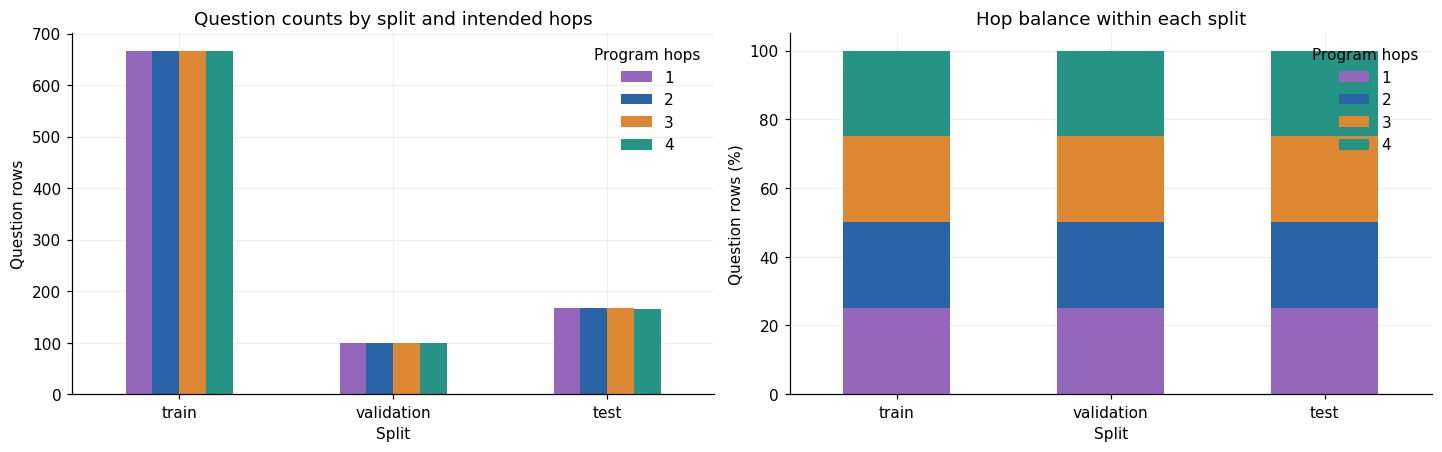

questions  \
hop_count composition_label                                                       
4         authored_by → works_at → located_in_city → city_in_country        246   
3         works_at → located_in_city → city_in_country                      224   
2         works_at → located_in_city                                        212   
4         produced_by → funded_by → based_in → city_in_country              210   
          cites → authored_by → works_at → located_in_city                  198   
...                                                                         ...   
1         based_in                                                           12   
          collaborates_with                                                   8   
4         inv:authored_by → produced_by → funded_by → based_in                4   
2         inv:authored_by → produced_by                                       2   
1         partners_with                                                       2   

                                                                      instances  \
hop_count composition_label                                                       
4         authored_by → works_at → located_in_city → city_in_country        123   
3         works_at → located_in_city → city_in_country                      112   
2         works_at → located_in_city                                        106   
4         produced_by → funded_by → based_in → city_in_country              105   
          cites → authored_by → works_at → located_in_city                   99   
...                                                                         ...   
1         based_in                                                            6   
          collaborates_with                                                   4   
4         inv:authored_by → produced_by → funded_by → based_in                2   
2         inv:authored_by → produced_by                                       1   
1         partners_with                                                       1   

                                                                      splits  
hop_count composition_label                                                   
4         authored_by → works_at → located_in_city → city_in_country       3  
3         works_at → located_in_city → city_in_country                     3  
2         works_at → located_in_city                                       3  
4         produced_by → funded_by → based_in → city_in_country             3  
          cites → authored_by → works_at → located_in_city                 3  
...                                                                      ...  
1         based_in                                                         3  
          collaborates_with                                                2  
4         inv:authored_by → produced_by → funded_by → based_in             2  
2         inv:authored_by → produced_by                                    1  
1         partners_with                                                    1  

[46 rows x 3 columns]

,questions,unique_instances,compositions
hop_count,,,
1,934,468,20
2,934,468,11
3,934,468,8
4,932,466,7


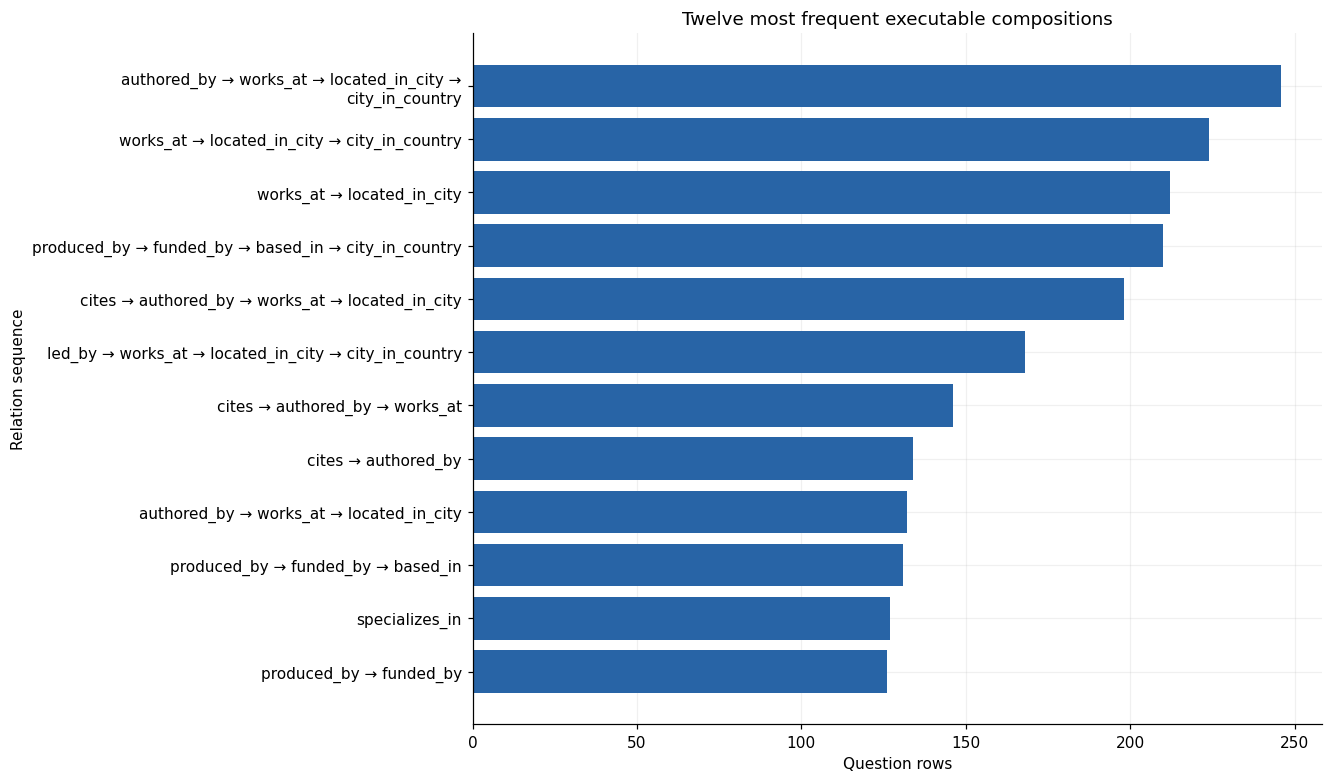

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
split_hops.plot.bar(ax=axes[0], color=[COLORS[h] for h in split_hops.columns], rot=0)
axes[0].set(title="Question counts by split and intended hops", xlabel="Split", ylabel="Question rows")
axes[0].legend(title="Program hops")
split_hops.div(split_hops.sum(axis=1), axis=0).mul(100).plot.bar(ax=axes[1], stacked=True, color=[COLORS[h] for h in split_hops.columns], rot=0)
axes[1].set(title="Hop balance within each split", xlabel="Split", ylabel="Question rows (%)", ylim=(0, 105))
axes[1].legend(title="Program hops")
finish(fig, "05_hop_split_distribution")
composition_counts = qa.groupby(["hop_count", "composition_label"]).agg(questions=("id", "size"), instances=("instance_key", "nunique"), splits=("split", "nunique")).sort_values("questions", ascending=False)
display(composition_counts)
display(qa.groupby("hop_count").agg(questions=("id", "size"), unique_instances=("instance_key", "nunique"), compositions=("composition", "nunique")))
fig, ax = plt.subplots(figsize=(12, 7))
top_compositions = qa.composition_label.value_counts().head(12).sort_values()
ax.barh([textwrap.fill(label, 55) for label in top_compositions.index], top_compositions.values, color="#2864a6")
ax.set(title="Twelve most frequent executable compositions", xlabel="Question rows", ylabel="Relation sequence")
finish(fig, "06_frequent_compositions")

,stored_triples,query_occurrences_including_inverse
relation,,
partners_with,28,2
collaborates_with,220,8
subfield_of,125,16
contributes_to,307,52
publication_field,400,53
specializes_in,700,127
investigates,303,172
cites,402,552
produced_by,400,593


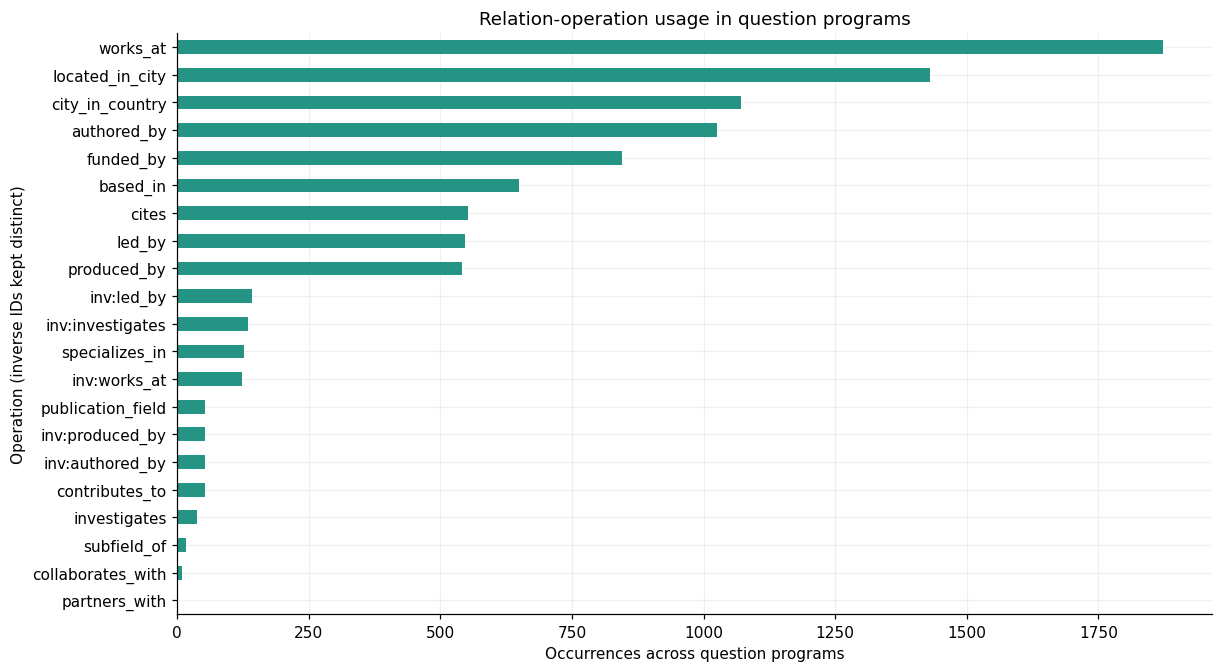

Stored relations absent from intended programs: none


In [9]:
operation_counts = pd.Series(Counter(op for path in qa.relation_path for op in path)).sort_values()
relation_coverage = pd.DataFrame({"stored_triples": triples.relation.value_counts()})
relation_coverage["query_occurrences_including_inverse"] = pd.Series(Counter(op.removeprefix("inv:") for path in qa.relation_path for op in path))
relation_coverage = relation_coverage.fillna(0).astype(int)
display(relation_coverage.sort_values("query_occurrences_including_inverse"))
unused_relations = relation_coverage.index[relation_coverage.query_occurrences_including_inverse == 0].tolist()
fig, ax = plt.subplots(figsize=(11, 6))
operation_counts.plot.barh(ax=ax, color="#259485")
ax.set(title="Relation-operation usage in question programs", xlabel="Occurrences across question programs", ylabel="Operation (inverse IDs kept distinct)")
finish(fig, "07_question_operation_usage")
print("Stored relations absent from intended programs:", ", ".join(unused_relations) or "none")

count  mean  median  max
split      hop_count                          
test       1            167  1.14     1.0    7
           2            167  1.13     1.0    5
           3            167  1.05     1.0    3
           4            166  1.20     1.0    5
train      1            667  1.13     1.0    7
           2            667  1.13     1.0    5
           3            667  1.14     1.0    6
           4            666  1.24     1.0    5
validation 1            100  1.14     1.0    7
           2            100  1.10     1.0    3
           3            100  1.28     1.0    5
           4            100  1.24     1.0    4

,answer_incidences,name,type
answer_id,,,
country_000040,44,Republic of Phathaepha 0041,country
country_000013,38,Republic of Vexzhaqor 0014,country
country_000037,36,Republic of Zhazaekyr 0038,country
country_000025,32,Republic of Thaexelpha 0026,country
country_000019,32,Republic of Lymkyrvex 0020,country
country_000030,32,Republic of Lymzaezae 0031,country
country_000017,30,Republic of Phathaeorv 0018,country
country_000039,30,Republic of Kyrnuvqor 0040,country
city_000150,28,City of Vexphapha 0151,city


,question_rows,distinct_instances,compositions,splits
answer_key,,,,
"(country_000040,)",44,22,4,3
"(country_000013,)",38,19,4,2
"(country_000037,)",32,16,6,2
"(country_000025,)",32,16,6,3
"(country_000017,)",30,15,6,3
"(country_000039,)",30,15,6,2
"(country_000019,)",30,15,7,3
"(country_000007,)",28,14,7,3
"(country_000030,)",28,14,7,3


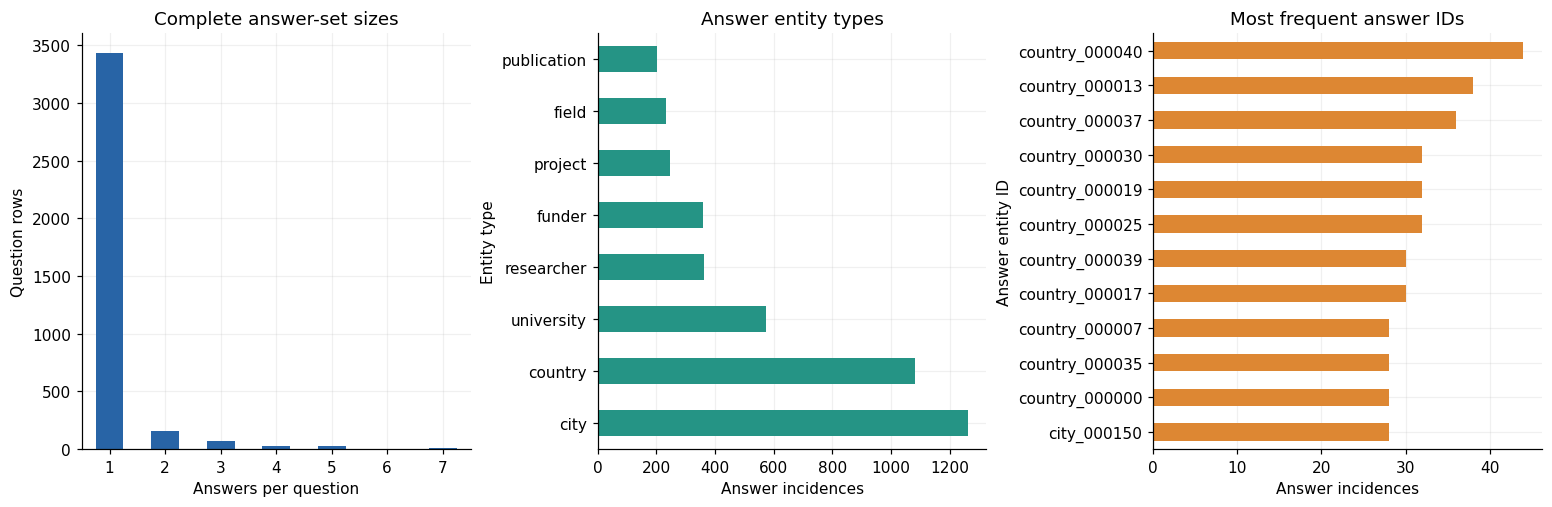

**8.09%** of question rows have multiple correct answers. The largest set contains **7** answers. Repeated answer sets are expected for shared countries, universities, or funders; repeated answers alone do not establish query leakage.

In [10]:
answer_rows = pd.DataFrame([{"question_id": q["id"], "split": q["split"], "hop_count": q["hop_count"],
    "answer_id": answer, "answer_type": graph.entities[answer]["type"]} for q in records for answer in q["answer_ids"]])
multi_pct = 100 * (qa.answer_count > 1).mean()
display(qa.groupby(["split", "hop_count"]).answer_count.agg(["count", "mean", "median", "max"]).round(2))
answer_frequencies = answer_rows.answer_id.value_counts()
top_answers = answer_frequencies.head(12).rename("answer_incidences").to_frame()
top_answers["name"] = [graph.entities[e]["name"] for e in top_answers.index]
top_answers["type"] = [graph.entities[e]["type"] for e in top_answers.index]
display(top_answers)
repeated_sets = qa.groupby("answer_key").agg(question_rows=("id", "size"), distinct_instances=("instance_key", "nunique"), compositions=("composition", "nunique"), splits=("split", "nunique")).sort_values("question_rows", ascending=False)
display(repeated_sets.head(10))
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
qa.answer_count.value_counts().sort_index().plot.bar(ax=axes[0], color="#2864a6", rot=0)
axes[0].set(title="Complete answer-set sizes", xlabel="Answers per question", ylabel="Question rows")
answer_rows.answer_type.value_counts().plot.barh(ax=axes[1], color="#259485")
axes[1].set(title="Answer entity types", xlabel="Answer incidences", ylabel="Entity type")
answer_frequencies.head(12).sort_values().plot.barh(ax=axes[2], color="#dd8733")
axes[2].set(title="Most frequent answer IDs", xlabel="Answer incidences", ylabel="Answer entity ID")
finish(fig, "08_answer_characteristics")
display(Markdown(f"**{multi_pct:.2f}%** of question rows have multiple correct answers. The largest set contains **{qa.answer_count.max()}** answers. Repeated answer sets are expected for shared countries, universities, or funders; repeated answers alone do not establish query leakage."))

,question_rows,name,type
start_entity,,,
publication_000050,12,Study Ithzhaorv 0051,publication
publication_000380,12,Study Thaexelpha 0381,publication
publication_000285,12,Study Nuvphaxel 0286,publication
publication_000119,12,Study Kyrqorzae 0120,publication
publication_000066,10,Study Qororvthae 0067,publication
publication_000144,10,Study Ithqorlym 0145,publication
publication_000236,10,Study Ithkyrorv 0237,publication
publication_000292,10,Study Lymxelzha 0293,publication
publication_000153,10,Study Thaexelzae 0154,publication


answer type(s),city,country,field,funder,project,publication,researcher,university
start_type,,,,,,,,
city,0,40,0,0,0,0,0,0
field,62,0,16,28,0,0,0,44
funder,12,37,0,0,0,0,0,0
project,229,272,38,58,0,52,50,102
publication,461,456,53,126,68,74,192,257
researcher,216,224,127,0,88,46,8,106
university,70,42,0,32,32,0,14,2


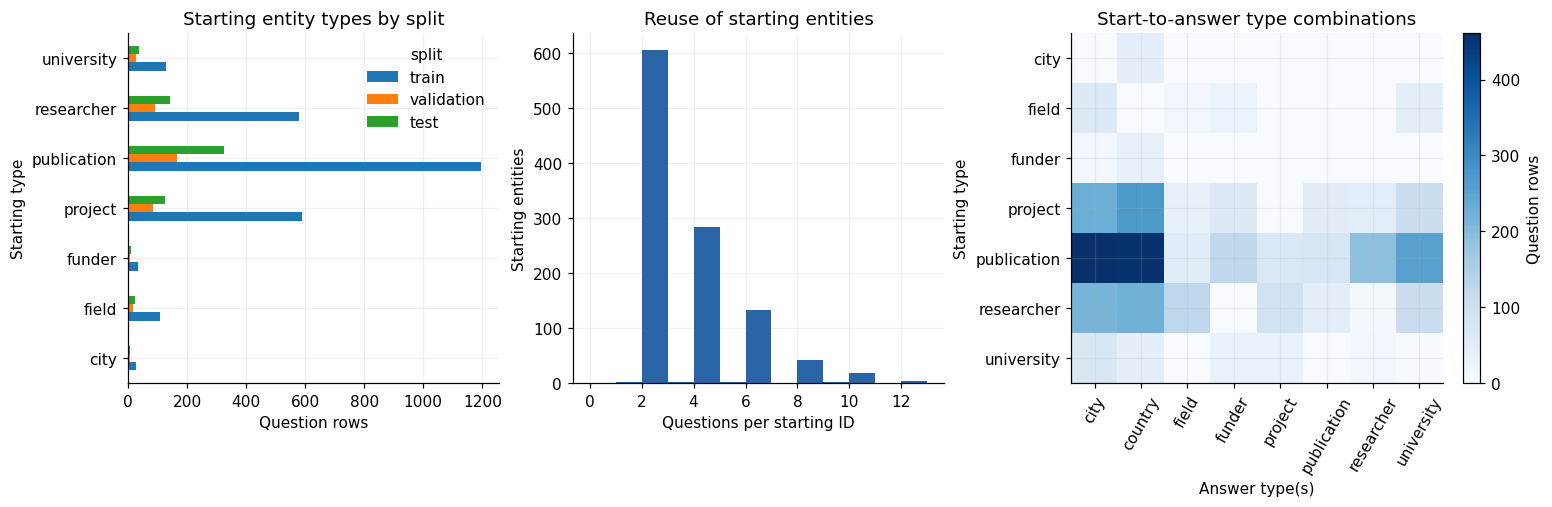

In [11]:
start_reuse = qa.start_entity.value_counts()
top_starts = start_reuse.head(12).rename("question_rows").to_frame()
top_starts["name"] = [graph.entities[e]["name"] for e in top_starts.index]
top_starts["type"] = [graph.entities[e]["type"] for e in top_starts.index]
display(top_starts)
type_pairs = pd.crosstab(qa.start_type, qa.answer_types.map(lambda ts: ", ".join(ts)))
display(type_pairs.rename_axis(columns="answer type(s)"))
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
pd.crosstab(qa.start_type, qa.split).reindex(columns=split_order).plot.barh(ax=axes[0])
axes[0].set(title="Starting entity types by split", xlabel="Question rows", ylabel="Starting type")
axes[1].hist(start_reuse, bins=range(int(start_reuse.max()) + 2), color="#2864a6")
axes[1].set(title="Reuse of starting entities", xlabel="Questions per starting ID", ylabel="Starting entities")
image = axes[2].imshow(type_pairs.values, cmap="Blues", aspect="auto")
axes[2].set(xticks=range(len(type_pairs.columns)), xticklabels=type_pairs.columns, yticks=range(len(type_pairs.index)), yticklabels=type_pairs.index,
    title="Start-to-answer type combinations", xlabel="Answer type(s)", ylabel="Starting type")
axes[2].tick_params(axis="x", rotation=60)
fig.colorbar(image, ax=axes[2], label="Question rows")
finish(fig, "09_starting_entities")

<a id="language"></a>
## 5. Language diversity, templates, and near duplicates

Question lengths use a lightweight Unicode word regex, **not** the future model tokenizer. Entity-masked patterns replace the known starting label/ID before normalization. These patterns measure grammar repetition, not semantic equivalence.

Type-token ratio (TTR) depends strongly on corpus size. We report raw values and equal-token-budget, seeded samples separately. Fictional names inflate raw vocabulary; the masked comparison exposes template vocabulary.

word_count                char_count                
                           mean median min max       mean median min  max
split      hop_count                                                     
test       1               7.98    8.0   5  11      52.08   51.0  31   75
           2              10.99   11.0   8  16      71.99   71.0  62  101
           3              13.60   14.0  10  16      90.19   88.0  80  107
           4              15.57   16.0  12  20     104.92  107.0  94  118
train      1               8.01    8.0   5  11      52.99   53.0  31   75
           2              10.88   11.0   8  16      72.09   71.0  62  100
           3              13.55   14.0  10  16      89.70   88.0  80  107
           4              15.47   16.0  12  20     104.77  106.0  94  120
validation 1               8.00    8.0   6  10      52.71   53.0  43   66
           2              10.90   11.0   9  13      71.88   71.0  62   93
           3              13.54   14.0  10  16      89.99   88.5  80  106
           4              15.60   16.0  12  18     105.58  109.0  94  118

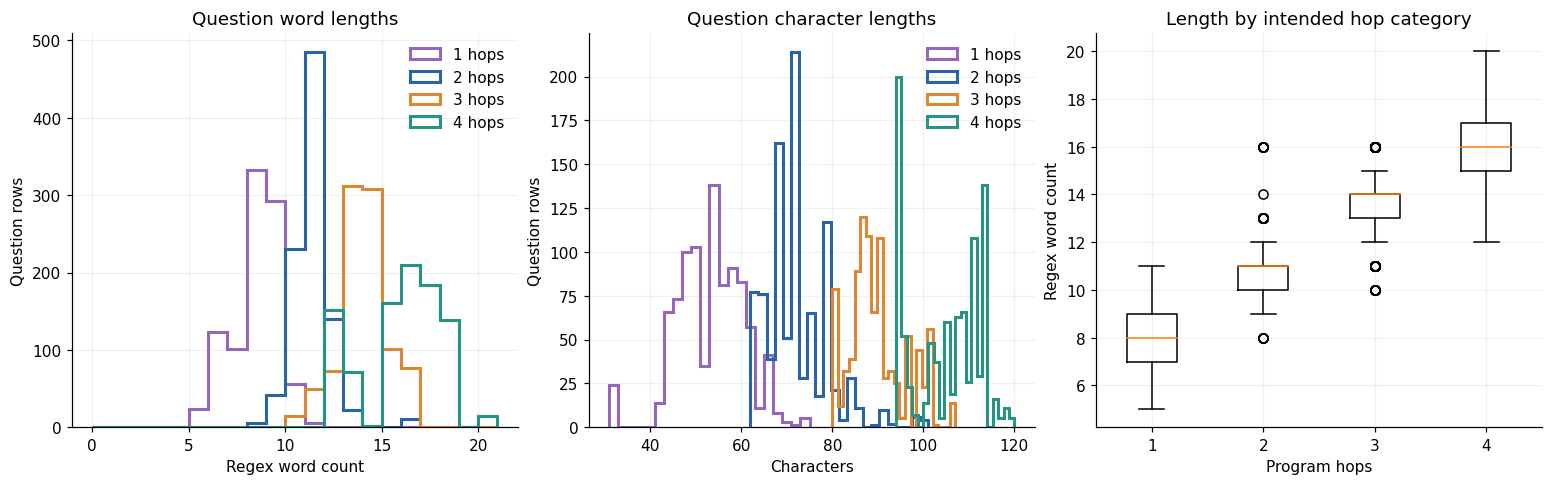

,split,tokens,vocabulary,raw_type_token_ratio,matched_raw_tokens,matched_raw_ttr,masked_tokens,masked_vocabulary,masked_raw_ttr,matched_masked_tokens,matched_masked_ttr
0,test,8024,611,0.0761,1500,0.2087,6639,106,0.0160,1500,0.0600
1,train,31941,1274,0.0399,1500,0.2073,26415,109,0.0041,1500,0.0613
2,validation,4804,441,0.0918,1500,0.1853,3966,99,0.0250,1500,0.0600


,questions,instances,split_count
template_pattern,,,
which countries contain cities hosting universities employing authors of entity,87,87,3
in which countries are the home cities of universities employing at least one author of entity,80,80,3
name the countries containing the home cities of universities where authors of entity work,79,79,3
in which countries is the university employing entity through its home city,79,79,3
name the home cities of the university that employs entity,77,77,3
name the countries containing cities where funders of the project that produced entity are based,73,73,3
name the countries containing the home city of the university employing entity,73,73,3
which countries contain the city hosting the university where entity works,72,72,3
in which countries are the home cities of organizations funding the project responsible for entity,71,71,3


Exact normalized duplicate text rows: 0
Distinct template IDs: 136
Distinct entity-masked patterns: 134


In [12]:
display(qa.groupby(["split", "hop_count"])[["word_count", "char_count"]].agg(["mean", "median", "min", "max"]).round(2))
fig, axes = plt.subplots(1, 3, figsize=(14, 4.3))
for hop, group in qa.groupby("hop_count"):
    axes[0].hist(group.word_count, bins=range(int(qa.word_count.max()) + 2), histtype="step", linewidth=2, color=COLORS[hop], label=f"{hop} hops")
    axes[1].hist(group.char_count, bins=22, histtype="step", linewidth=2, color=COLORS[hop], label=f"{hop} hops")
axes[0].set(title="Question word lengths", xlabel="Regex word count", ylabel="Question rows")
axes[1].set(title="Question character lengths", xlabel="Characters", ylabel="Question rows")
axes[0].legend(); axes[1].legend()
axes[2].boxplot([qa.loc[qa.hop_count == h, "word_count"] for h in [1, 2, 3, 4]], labels=["1", "2", "3", "4"])
axes[2].set(title="Length by intended hop category", xlabel="Program hops", ylabel="Regex word count")
finish(fig, "10_question_lengths")
lexical = lexical_summary(qa, seed=SEED)
display(lexical.round(4))
patterns = qa.groupby("template_pattern").agg(questions=("id", "size"), instances=("instance_key", "nunique"), split_count=("split", "nunique")).sort_values("questions", ascending=False)
display(patterns.head(12))
print("Exact normalized duplicate text rows:", int(qa.text_key.duplicated().sum()))
print("Distinct template IDs:", qa.template_id.nunique() if "template_id" in qa else "metadata unavailable")
print("Distinct entity-masked patterns:", qa.template_pattern.nunique())

### Bounded near-duplicate screen

Candidates are blocked by entity-masked text or executable composition. At most six candidates per row per block are sampled deterministically, preferring other splits when available. Actual unmasked word-set Jaccard similarity is then computed. This avoids an all-pairs comparison and targets plausible template similarities.

The 0.82 review threshold is a configurable lexical heuristic. The screen is **not exhaustive**, does not estimate a population duplicate rate, and can miss semantic paraphrases or similarities outside these blocks. Shared text patterns are interpreted alongside exact query keys in the leakage section.

,screen result
Candidate pairs screened,34720
Pairs above review threshold,10
Above-threshold cross-split pairs,10
Above-threshold same-instance pairs,0


**Most similar screened pairs** (shown even if the review threshold is not crossed):

,left_id,right_id,left_split,right_split,jaccard,near_duplicate,same_instance,left_question,right_question
23673,q_001809,q_002669,train,test,0.888889,True,False,In which countries are the home cities of universities employing at least one leader of Project ...,In which countries are the home cities of universities employing at least one leader of Project ...
9744,q_000773,q_002500,train,test,0.875000,True,False,At which universities do authors of at least one publication cited in Study Thaeithxel 0179 work?,At which universities do authors of at least one publication cited in Study Thaeithxel 0300 work?
14191,q_001112,q_002541,train,test,0.866667,True,False,"In which countries is the university employing Dr. Nuvxelqor 0420, through its home city?","In which countries is the university employing Dr. Nuvxelqor 0030, through its home city?"
20857,q_001606,q_002640,train,test,0.866667,True,False,Name the countries containing the home cities of universities where authors of Study Zhazhakyr 0...,Name the countries containing the home cities of universities where authors of Study Zhazhakyr 0...
10067,q_000799,q_002135,train,validation,0.846154,True,False,Name the countries containing the home city of the university employing Dr. Zhaxellym 0233.,Name the countries containing the home city of the university employing Dr. Zhaxellym 0240.
14099,q_001105,q_002540,train,test,0.846154,True,False,Which countries contain the city hosting the university where Dr. Nuvxelqor 0319 works?,Which countries contain the city hosting the university where Dr. Nuvxelqor 0030 works?
14140,q_001108,q_002566,train,test,0.846154,True,False,Which countries contain the city hosting the university where Dr. Nuvthaeith 0211 works?,Which countries contain the city hosting the university where Dr. Nuvthaeith 0025 works?
308,q_000025,q_002309,train,test,0.833333,True,False,At which universities do the leaders of Project Orvnuvkyr 0264 work?,At which universities do the leaders of Project Orvnuvkyr 0031 work?


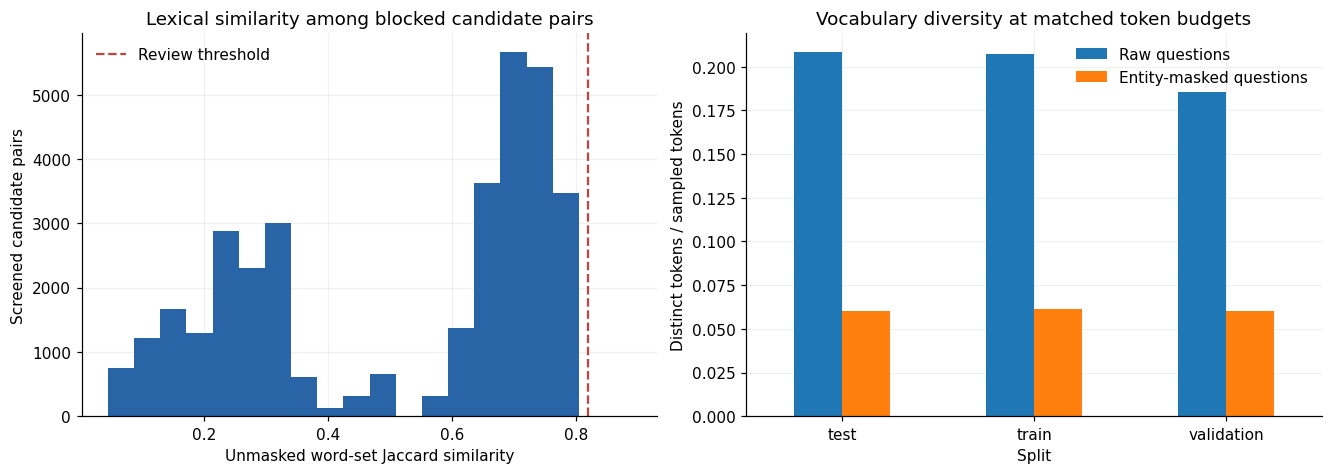

In [13]:
near_pairs = near_duplicate_screen(qa, seed=SEED, threshold=NEAR_DUPLICATE_JACCARD, candidates_per_row=NEAR_DUPLICATE_CANDIDATES_PER_ROW)
near_matches = near_pairs.loc[near_pairs.near_duplicate].sort_values(["jaccard", "left_id"], ascending=[False, True])
display(pd.Series({"Candidate pairs screened": len(near_pairs), "Pairs above review threshold": len(near_matches),
    "Above-threshold cross-split pairs": int((near_matches.left_split != near_matches.right_split).sum()),
    "Above-threshold same-instance pairs": int(near_matches.same_instance.sum())}, name="screen result").to_frame())
display(Markdown("**Most similar screened pairs** (shown even if the review threshold is not crossed):"))
display(near_pairs.sort_values(["jaccard", "left_id"], ascending=[False, True])[["left_id", "right_id", "left_split", "right_split", "jaccard", "near_duplicate", "same_instance", "left_question", "right_question"]].head(8))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].hist(near_pairs.jaccard, bins=20, color="#2864a6")
axes[0].axvline(NEAR_DUPLICATE_JACCARD, color="#b64a44", linestyle="--", label="Review threshold")
axes[0].set(title="Lexical similarity among blocked candidate pairs", xlabel="Unmasked word-set Jaccard similarity", ylabel="Screened candidate pairs")
axes[0].legend()
lexical.set_index("split")[["matched_raw_ttr", "matched_masked_ttr"]].plot.bar(ax=axes[1], rot=0)
axes[1].set(title="Vocabulary diversity at matched token budgets", xlabel="Split", ylabel="Distinct tokens / sampled tokens")
axes[1].legend(["Raw questions", "Entity-masked questions"])
finish(fig, "11_language_similarity")

<a id="difficulty"></a>
## 6. Navigation difficulty and independent metadata checks

The existing discovery-gated `execute` function is rerun for every unique start/program pair. Complete answers, saved edges, difficulty fields, and shortest-distance metadata are compared with the graph. The existing full validator is also called **in memory**, when its optional metadata is present. No validator CLI is used because that CLI writes reports into the source data directory.

Three different measures are retained:

1. **Intended/semantic program hops:** length of the executable relation composition bound to the question template. The existing validator checks catalog correspondence; this is not an unrestricted proof of English semantics.
2. **Shortest graph distance:** minimum navigable edge count to a particular recorded answer, ignoring relation meaning. It does not prove that another route answers the same question or recovers the full set.
3. **Reference tool calls:** actual `get_relations`/`get_neighbors` calls of the gold executor plus submission. It excludes label lookups, errors, and uninformed search. An agent's required exploration cost cannot be inferred from this metadata.

Frontier traces below count unique query instances once, avoiding double-counting paraphrases. Branching counts available operation-neighbor choices, rather than only distinct endpoint nodes.

Some frontier entities are dead ends for the intended operation, so the mean relevant-neighbor count can fall below one. These traces include unsuccessful candidate branches as well as the saved successful witnesses.

In [14]:
audit, frontier_trace, full_validation = navigation_audit(graph, records, run_full_validation=RUN_FULL_VALIDATION, config=config)
qa = qa.merge(audit.drop(columns=["recomputed_paths"]), on="id", how="left", validate="one_to_one")
display(pd.Series({
    "Core-valid question rows": int(audit.core_valid.sum()), "Core-invalid rows": int((~audit.core_valid).sum()),
    "Saved witness edge/coverage errors": int(audit.witness_errors.sum()),
    "Difficulty field mismatches": int(audit.difficulty_mismatches.sum()),
    "Shortest-distance metadata mismatches": int(audit.shortest_metadata_mismatch.sum()),
    "Difficulty metadata present": int(audit.difficulty_metadata_present.sum()),
    "Unique query frontier visits": len(frontier_trace),
    "Full validator available": full_validation["available"],
    "Full validator error count": len(full_validation.get("errors", [])),
}, name="observed").to_frame())
if full_validation.get("errors"):
    display(pd.DataFrame(full_validation["errors"]).head(20))
if not full_validation["available"]:
    display(Markdown(full_validation["reason"]))
display(qa.groupby("hop_count")[["branching_factor", "relation_options_mean", "query_neighbors_mean", "distractor_count", "reference_tool_calls", "shortest_mean"]].agg(["mean", "median", "max"]).round(2))

,observed
Core-valid question rows,3734
Core-invalid rows,0
Saved witness edge/coverage errors,0
Difficulty field mismatches,0
Shortest-distance metadata mismatches,0
Difficulty metadata present,3734
Unique query frontier visits,5376
Full validator available,True
Full validator error count,0


branching_factor              relation_options_mean               \
                      mean median   max                  mean median   max   
hop_count                                                                    
1                     5.02   5.00  15.0                  4.21    5.0  6.00   
2                     5.49   5.00   9.0                  3.92    4.5  5.50   
3                     5.35   5.33   9.0                  3.68    4.0  5.33   
4                     5.40   5.25   9.5                  3.66    3.5  4.75   

          query_neighbors_mean              distractor_count             \
                          mean median   max             mean median max   
hop_count                                                                 
1                         1.13    1.0  7.00             3.89    4.0  14   
2                         1.03    1.0  1.60             9.85    8.0  31   
3                         1.02    1.0  1.38            14.51   13.0  49   
4                         1.02    1.0  1.33            21.31   18.0  82   

          reference_tool_calls            shortest_mean              
                          mean median max          mean median  max  
hop_count                                                            
1                         3.00    3.0   3          1.00    1.0  1.0  
2                         5.37    5.0  15          2.00    2.0  2.0  
3                         7.63    7.0  25          2.95    3.0  3.0  
4                        10.57    9.0  35          3.93    4.0  4.0

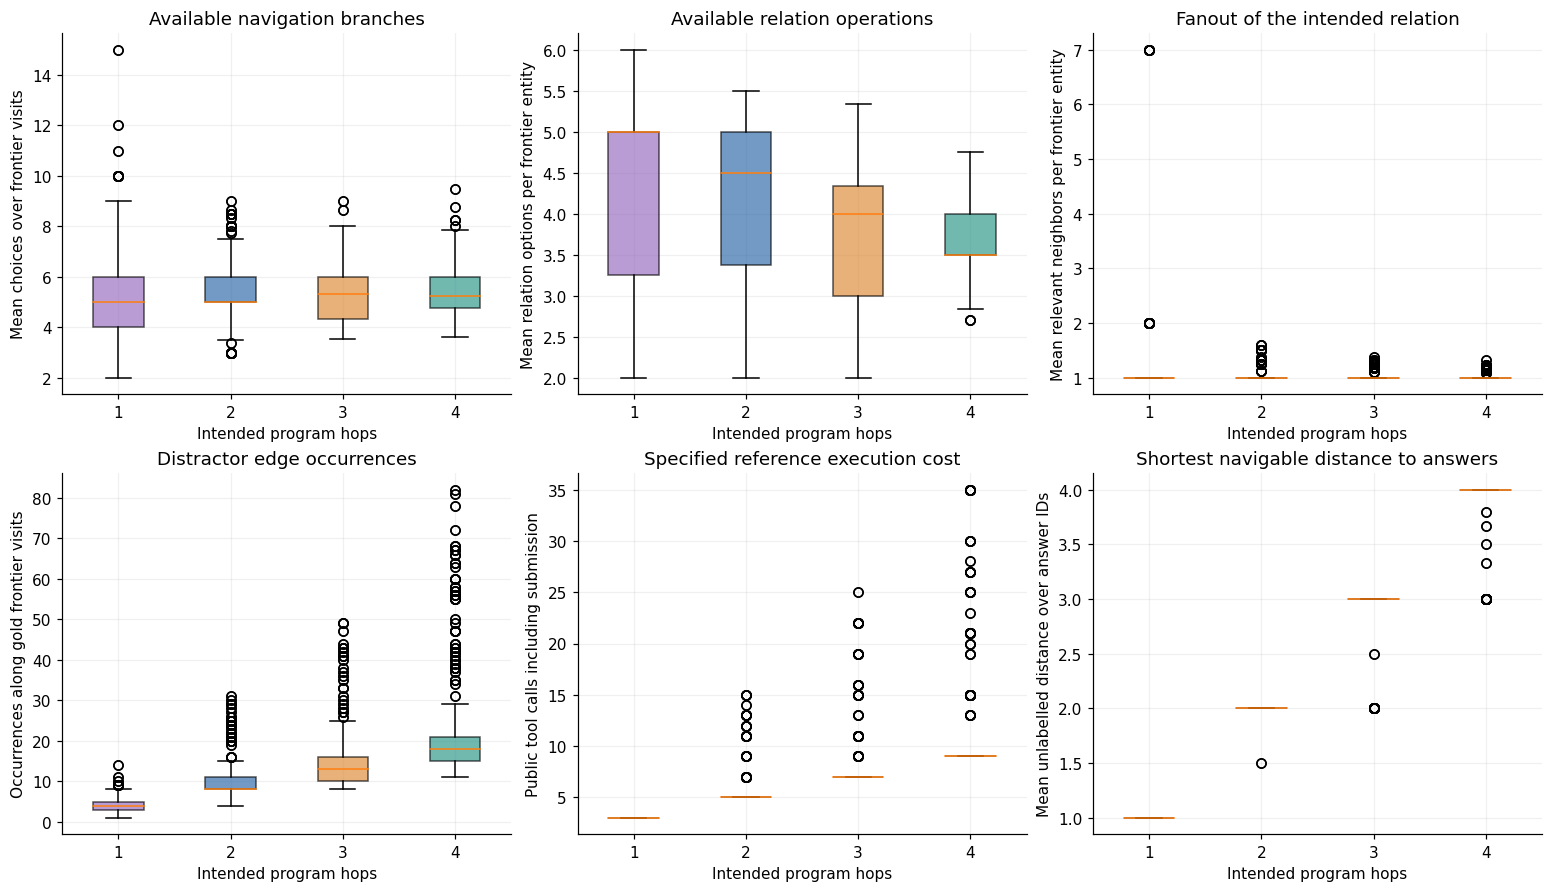

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
metrics = [
    ("branching_factor", "Available navigation branches", "Mean choices over frontier visits"),
    ("relation_options_mean", "Available relation operations", "Mean relation options per frontier entity"),
    ("query_neighbors_mean", "Fanout of the intended relation", "Mean relevant neighbors per frontier entity"),
    ("distractor_count", "Distractor edge occurrences", "Occurrences along gold frontier visits"),
    ("reference_tool_calls", "Specified reference execution cost", "Public tool calls including submission"),
    ("shortest_mean", "Shortest navigable distance to answers", "Mean unlabelled distance over answer IDs"),
]
for ax, (metric, title, ylabel) in zip(axes.flat, metrics):
    box = ax.boxplot([qa.loc[qa.hop_count == h, metric].dropna() for h in [1, 2, 3, 4]], labels=["1", "2", "3", "4"], patch_artist=True)
    for patch, hop in zip(box["boxes"], [1, 2, 3, 4]):
        patch.set_facecolor(COLORS[hop]); patch.set_alpha(.65)
    ax.set(title=title, xlabel="Intended program hops", ylabel=ylabel)
finish(fig, "12_navigation_difficulty_by_hops")

available_relations            candidate_neighbors             \
                              mean median max                mean median max   
hop_count step                                                                 
1         1                   4.21    5.0   6                1.13    1.0   7   
2         1                   4.05    5.0   6                1.26    1.0   7   
          2                   3.74    5.0   6                0.89    1.0   2   
3         1                   4.27    5.0   6                1.25    1.0   7   
          2                   3.94    5.0   6                0.90    1.0   2   
          3                   3.02    2.0   6                1.01    1.0   2   
4         1                   4.46    5.0   5                1.39    1.0   7   
          2                   4.74    5.0   6                0.89    1.0   2   
          3                   3.46    3.0   6                1.00    1.0   2   
          4                   2.04    2.0   3                1.00    1.0   1   

               distracting_relations            distractor_branches             
                                mean median max                mean median max  
hop_count step                                                                  
1         1                     3.21    4.0   5                3.89    4.0  14  
2         1                     3.05    4.0   5                4.01    4.0  13  
          2                     2.85    4.0   5                4.64    5.0  10  
3         1                     3.27    4.0   5                3.92    4.0  11  
          2                     3.04    4.0   5                4.92    5.0  10  
          3                     2.02    1.0   5                3.91    4.0  10  
4         1                     3.46    4.0   4                4.33    4.0  15  
          2                     3.86    4.0   5                4.58    5.0  10  
          3                     2.46    2.0   5                5.33    5.0  10  
          4                     1.04    1.0   2                3.24    1.0  10

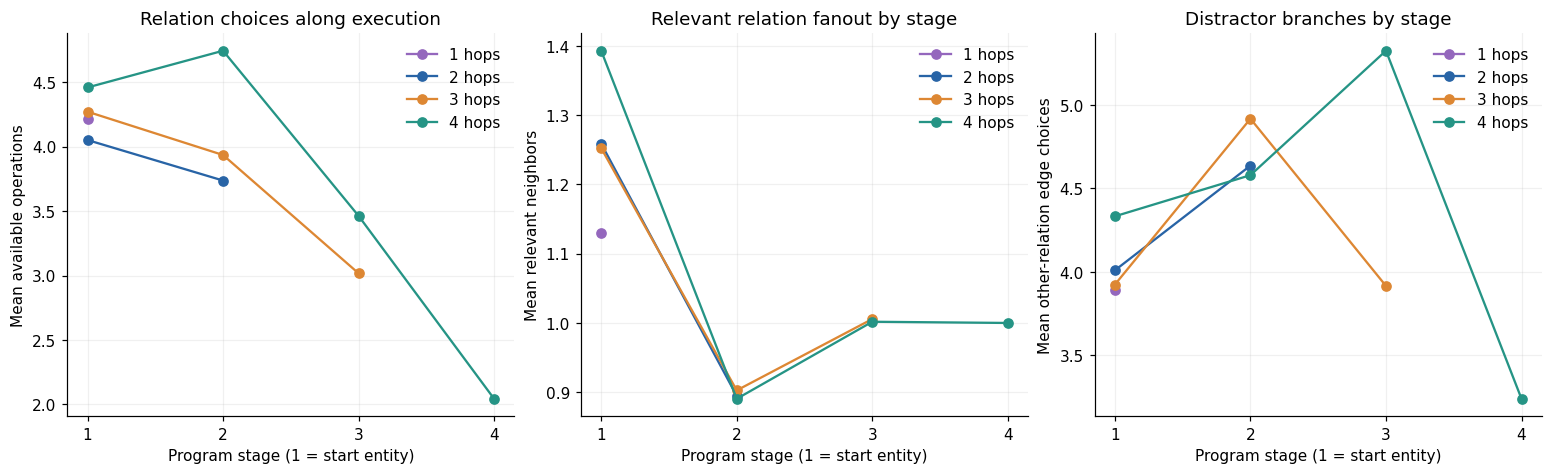

minimum unlabelled answer distance,1,2,3,4
hop_count,,,,
1,934,0,0,0
2,2,932,0,0
3,0,44,890,0
4,0,0,68,864


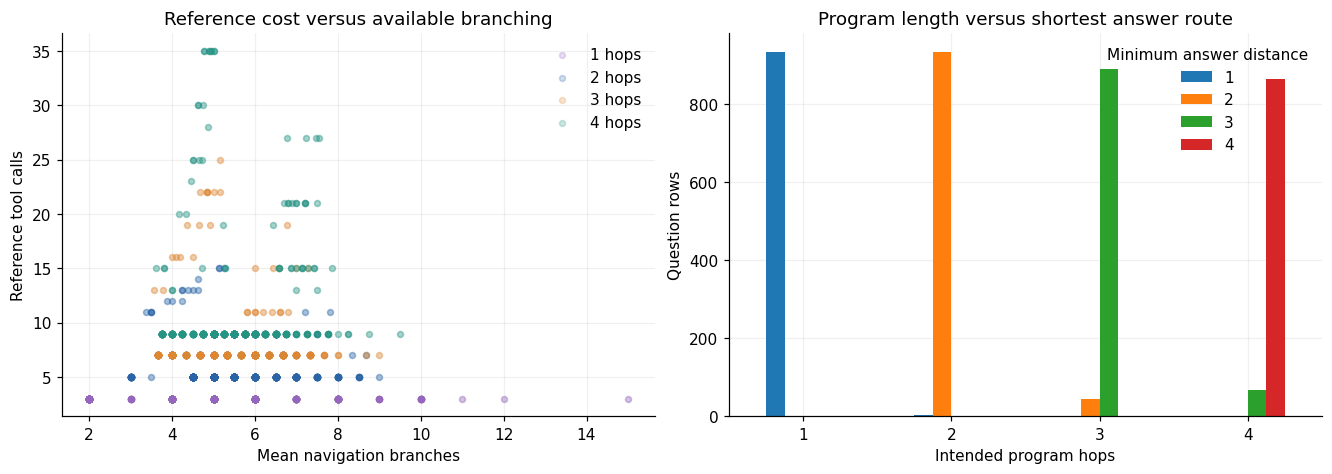

In [16]:
frontier_summary = frontier_trace.groupby(["hop_count", "step"])[["available_relations", "candidate_neighbors", "distracting_relations", "distractor_branches"]].agg(["mean", "median", "max"])
display(frontier_summary.round(2))
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for hop, group in frontier_trace.groupby("hop_count"):
    profile = group.groupby("step")[["available_relations", "candidate_neighbors", "distractor_branches"]].mean()
    for ax, metric in zip(axes, profile.columns):
        ax.plot(profile.index, profile[metric], marker="o", label=f"{hop} hops", color=COLORS[hop])
for ax, title, ylabel in zip(axes, ["Relation choices along execution", "Relevant relation fanout by stage", "Distractor branches by stage"],
        ["Mean available operations", "Mean relevant neighbors", "Mean other-relation edge choices"]):
    ax.set(title=title, xlabel="Program stage (1 = start entity)", ylabel=ylabel, xticks=[1, 2, 3, 4])
    ax.legend()
finish(fig, "13_frontier_profiles")
# The comparison below is question-level: minimum and maximum distances across all answers.
distance_crosstab = pd.crosstab(qa.hop_count, qa.shortest_min).rename_axis(columns="minimum unlabelled answer distance")
display(distance_crosstab)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for hop, group in qa.groupby("hop_count"):
    axes[0].scatter(group.branching_factor, group.reference_tool_calls, s=15, alpha=.23, color=COLORS[hop], label=f"{hop} hops")
axes[0].set(title="Reference cost versus available branching", xlabel="Mean navigation branches", ylabel="Reference tool calls")
axes[0].legend()
distance_crosstab.plot.bar(ax=axes[1], rot=0)
axes[1].set(title="Program length versus shortest answer route", xlabel="Intended program hops", ylabel="Question rows")
axes[1].legend(title="Minimum answer distance")
finish(fig, "14_hops_distance_and_cost")

In [17]:
extreme_columns = ["id", "split", "hop_count", "question", "answer_count", "branching_factor", "relation_options_mean", "query_neighbors_mean", "reference_tool_calls", "shortest_min"]
display(Markdown("**Highest reference execution costs** (a specified algorithm, not measured model search):"))
display(qa.sort_values(["reference_tool_calls", "branching_factor", "id"], ascending=[False, False, True])[extreme_columns].head(6))
display(Markdown("**Lowest available branching within each hop category:**"))
display(qa.sort_values(["branching_factor", "reference_tool_calls", "id"]).groupby("hop_count", sort=True).head(2)[extreme_columns])
decisionless_instances = frontier_trace.groupby("instance_key").navigation_branches.max().le(1)
single_query_neighbor_instances = frontier_trace.groupby("instance_key").candidate_neighbors.max().le(1)
print("Instances with at most one total navigation branch at every visited frontier:", int(decisionless_instances.sum()))
print("Instances with at most one relevant neighbor at each visited frontier:", int(single_query_neighbor_instances.sum()))
display(Markdown("A single relevant neighbor can coexist with many distracting relations. The second count alone does **not** identify trivial questions. No agent exploration-call estimate, empirical success rate, or token-memory cost is available."))

**Highest reference execution costs** (a specified algorithm, not measured model search):

,id,split,hop_count,question,answer_count,branching_factor,relation_options_mean,query_neighbors_mean,reference_tool_calls,shortest_min
2123,q_001457,train,4,Name the home cities of organizations funding projects with a leader employed by University of T...,5,5.000000,3.722222,1.222222,35,4
2124,q_001458,train,4,In which cities are funders of projects led by at least one researcher employed at University of...,5,5.000000,3.722222,1.222222,35,4
2403,q_001737,train,4,Name the home cities of organizations funding projects with a leader employed by University of Z...,5,5.000000,3.722222,1.222222,35,4
2404,q_001738,train,4,In which cities are funders of projects led by at least one researcher employed at University of...,5,5.000000,3.722222,1.222222,35,4
2303,q_001637,train,4,In which cities are funders of projects led by at least one researcher employed at University of...,5,4.944444,3.722222,1.222222,35,4
2304,q_001638,train,4,Name the home cities of organizations funding projects with a leader employed by University of T...,5,4.944444,3.722222,1.222222,35,4


**Lowest available branching within each hop category:**

,id,split,hop_count,question,answer_count,branching_factor,relation_options_mean,query_neighbors_mean,reference_tool_calls,shortest_min
2671,q_002805,train,1,At which university does Dr. Thaeqorvex 0302 work?,1,2.000000,2.000000,1.0,3,1
2672,q_002806,train,1,Name the university where Dr. Thaeqorvex 0302 is employed.,1,2.000000,2.000000,1.0,3,1
699,q_000033,train,2,Name the countries containing the home city of Research Trust Ithzhaith 0025.,1,3.000000,2.000000,1.0,5,2
700,q_000034,train,2,Which countries contain the city where Research Trust Ithzhaith 0025 is based?,1,3.000000,2.000000,1.0,5,2
217,q_002518,test,3,Which funding organizations sponsor projects led by at least one employee of University of Phaor...,1,3.555556,2.777778,1.0,13,3
218,q_002519,test,3,Name the funders of projects with at least one leader working at University of Phaorvqor 0086.,1,3.555556,2.777778,1.0,13,3
404,q_002705,test,4,Name the home cities of organizations funding projects with a leader employed by University of L...,1,3.600000,2.700000,1.0,15,4
405,q_002706,test,4,In which cities are funders of projects led by at least one researcher employed at University of...,1,3.600000,2.700000,1.0,15,4


Instances with at most one total navigation branch at every visited frontier: 0
Instances with at most one relevant neighbor at each visited frontier: 1710


A single relevant neighbor can coexist with many distracting relations. The second count alone does **not** identify trivial questions. No agent exploration-call estimate, empirical success rate, or token-memory cost is available.

<a id="leakage"></a>
## 7. Split overlap and leakage

Identical normalized question text or identical derived query instances across splits are problematic. Starting entities, answers, relations, composition templates, and factual edges may overlap by design. A reference path key includes both entity IDs and operations; a shared entity sequence using different relations is not silently treated as identical.

The optional composition holdout, when loaded, should have zero composition overlap with ordinary splits. Ordinary random-instance splitting is not a fact-disjoint or grammar-disjoint evaluation.

item              answer_entity  composition  query_instance  question_text  \
left  right                                                                   
test  train                 185           43               0              0   
      validation             67           40               0              0   
train validation            129           39               0              0   

item              reference_path  start_entity  template_id  template_pattern  
left  right                                                                    
test  train                    0           166          124               122  
      validation               0            34          110               108  
train validation               0           102          111               109

,left,right,item,shared,left_unique,right_unique,right_covered_pct
4,test,train,composition,43,44,45,95.56
5,test,train,template_pattern,122,124,131,93.13
7,test,train,reference_path,0,379,1547,0.00
12,test,validation,composition,40,44,40,100.00
13,test,validation,template_pattern,108,124,111,97.30
15,test,validation,reference_path,0,379,238,0.00
20,train,validation,composition,39,45,40,97.50
21,train,validation,template_pattern,109,131,111,98.20
23,train,validation,reference_path,0,1547,238,0.00


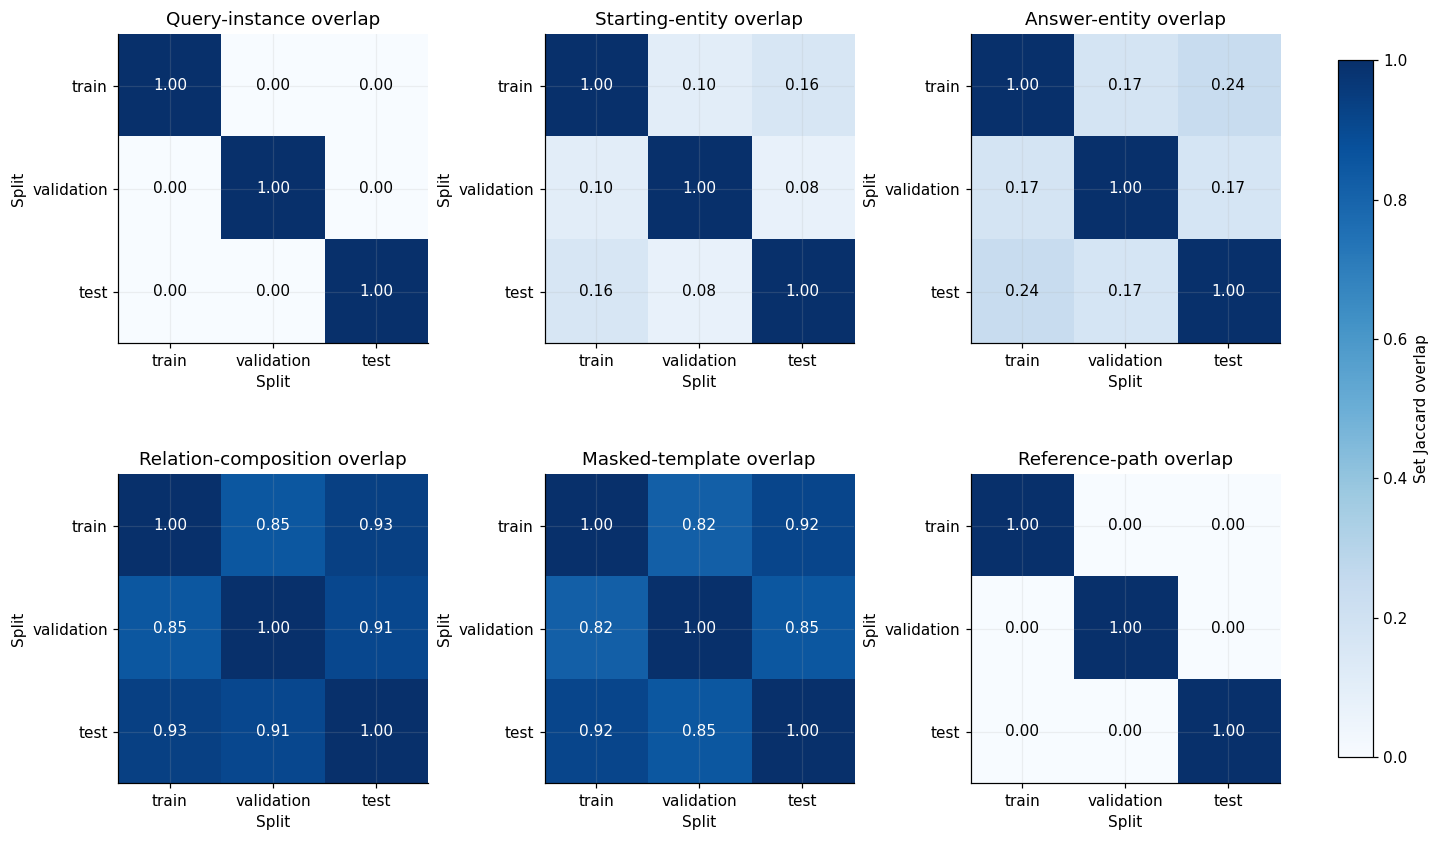

The pairwise audit finds **0 shared exact-text keys** and **0 shared underlying query-instance keys**. Other overlap values describe what is shared; they are not automatically failures. The bounded lexical screen found **10** cross-split pairs above the configured similarity threshold among its screened candidates, which should be interpreted as grammar similarity unless exact query keys also match.

In [18]:
overlaps, overlap_sets = split_overlaps(qa)
display(overlaps.pivot(index=["left", "right"], columns="item", values="shared").fillna(0).astype(int))
display(overlaps.loc[overlaps.item.isin(["composition", "template_pattern", "reference_path"]), ["left", "right", "item", "shared", "left_unique", "right_unique", "right_covered_pct"]].round(2))
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, item, title in zip(axes.flat, ["query_instance", "start_entity", "answer_entity", "composition", "template_pattern", "reference_path"],
        ["Query-instance overlap", "Starting-entity overlap", "Answer-entity overlap", "Relation-composition overlap", "Masked-template overlap", "Reference-path overlap"]):
    matrix = pd.DataFrame(0.0, index=split_order, columns=split_order)
    for left in split_order:
        for right in split_order:
            a, b = overlap_sets[left][item], overlap_sets[right][item]
            matrix.loc[left, right] = len(a & b) / len(a | b) if a | b else 0
    image = ax.imshow(matrix, vmin=0, vmax=1, cmap="Blues")
    ax.set(title=title, xticks=range(len(split_order)), xticklabels=split_order, yticks=range(len(split_order)), yticklabels=split_order,
           xlabel="Split", ylabel="Split")
    for i in range(len(split_order)):
        for j in range(len(split_order)):
            ax.text(j, i, f"{matrix.iloc[i,j]:.2f}", ha="center", va="center", color="white" if matrix.iloc[i,j] > .55 else "black")
fig.colorbar(image, ax=list(axes.flat), label="Set Jaccard overlap", shrink=.8)
finish(fig, "15_split_overlap")
cross_text = int(overlaps.loc[overlaps.item == "question_text", "shared"].sum())
cross_instances = int(overlaps.loc[overlaps.item == "query_instance", "shared"].sum())
display(Markdown(f"The pairwise audit finds **{cross_text} shared exact-text keys** and **{cross_instances} shared underlying query-instance keys**. Other overlap values describe what is shared; they are not automatically failures. The bounded lexical screen found **{int((near_matches.left_split != near_matches.right_split).sum())}** cross-split pairs above the configured similarity threshold among its screened candidates, which should be interpreted as grammar similarity unless exact query keys also match."))

<a id="examples"></a>
## 8. Fifteen reproducible question inspections

Five rows are sampled independently from each hop category, using `SEED + hop` and a stable ID ordering. Each card re-executes its program, shows the complete answer set, and presents one verified witness per answer. These are private EDA outputs, not model prompts. If optional saved paths are absent, the existing executor supplies a witness in memory.

In [19]:
samples = stratified_samples(qa, per_hop=SAMPLES_PER_HOP, seed=SEED)
display(samples.groupby("hop_count").size().rename("sampled questions").to_frame())
display(samples[["id", "split", "hop_count", "start_entity", "answer_count", "branching_factor", "reference_tool_calls", "core_valid"]])
audit_by_id = audit.set_index("id")
for row in samples.itertuples():
    display(HTML(question_html(graph, record_by_id[row.id], audit_by_id.loc[row.id].to_dict())))

,sampled questions
hop_count,
1,5
2,5
3,5
4,5


,id,split,hop_count,start_entity,answer_count,branching_factor,reference_tool_calls,core_valid
2737,q_002871,train,1,researcher_000188,1,2.000000,3,True
2876,q_003010,train,1,publication_000175,1,7.000000,3,True
2988,q_003122,train,1,publication_000385,1,4.000000,3,True
3216,q_003350,train,1,researcher_000456,1,5.000000,3,True
3678,q_003512,validation,1,project_000280,1,5.000000,3,True
856,q_000190,train,2,publication_000176,1,5.000000,5,True
960,q_000294,train,2,publication_000260,1,5.000000,5,True
1131,q_000465,train,2,researcher_000614,1,6.500000,5,True
1133,q_000467,train,2,publication_000009,1,6.500000,5,True
1279,q_000613,train,2,publication_000358,1,4.500000,5,True


<a id="protege"></a>
## 9. Graph inspection in Protégé

Open **`data/graph/graph.ttl`** (or `DATA_DIR / "graph/graph.ttl"` for another dataset) in Protégé. This self-contained Turtle file includes the OWL ontology, all entity labels/types and all asserted graph edges, so no remote imports are needed. Use the Classes, Object properties and Individuals views.

Entity IRIs preserve the existing IDs under `https://example.org/kg-navigation-rlvr/entity/`. The `kg:` prefix identifies ontology classes and relations. Inverse properties carry labels such as `inv:works_at`; their OWL declarations do not add inferred edges to model navigation. Python validation still enforces the project's closed-world constraints.

The custom graph renderer and its interactive widgets have been removed. Statistical charts and the textual question/witness inspections above remain available.

<a id="quality"></a>
## 10. Dataset quality assessment

**FAIL** is reserved for a violated correctness requirement or a saved generation limit. **REVIEW** identifies a potential research concern without inventing a universal acceptable threshold. **UNAVAILABLE** means the required metadata/check is missing, not that it passed. Sparse relations, repeated grammar, or a low reference-call count are not automatically invalid.

In [20]:
quality = quality_assessment(graph, qa, audit, schema, overlaps, config, full_validation)
display(quality.style.set_properties(**{"text-align": "left", "white-space": "normal", "overflow-wrap": "anywhere"}).set_table_styles([{"selector": "th", "props": [("text-align", "left")]}]))
limitations = pd.DataFrame([
    ("Uninformed agent exploration cost", "Unavailable: no agent trajectories or search policy were collected. Reference calls are measured separately."),
    ("Empirical model difficulty", "Unavailable: no model accuracy, training, or behavioral baseline is run here."),
    ("Tokenizer/context memory", "Unavailable: word counts and neighbor cardinalities are not model-token or GPU-memory measurements."),
    ("English semantic proof", "Catalog/template binding can be checked; arbitrary natural-language equivalence is not proven."),
    ("Exhaustive near-duplicate detection", "Not performed: the bounded lexical screen is candidate-biased and may miss paraphrases."),
    ("Browser event validation", "Python execution verifies exports, payloads, and iframe construction. Actual rendering/events need a trusted browser frontend."),
], columns=["analysis", "limitation"])
display(limitations)

,check,observed,expectation,status,explanation
0,Required schema/reference issues,0,0,PASS,"Invalid identifiers, types, or schema undermine executable verification."
1,Question execution / metadata failures,0,0,PASS,"Recomputed complete answers, saved witnesses, and available difficulty/distance fields."
2,Full existing validator,0,0 errors,PASS,"Includes ontology constraints, template/program binding, grouping, and shorter-equivalent-program checks; missing optional fields limit this audit."
3,Cross-split identical text,0,0 shared pairwise keys,PASS,Counts shared keys per split pair; one key can contribute to multiple pairs.
4,Cross-split query instances,0,0 shared pairwise keys,PASS,Counts shared keys per split pair; one key can contribute to multiple pairs.
5,Weak components,1,Prefer a connected navigation ecosystem,PASS,Disconnected islands can constrain reachable tasks; not automatically invalid.
6,Isolated entities,0,Prefer 0,PASS,An isolated entity cannot support a positive-length traversal task.
7,Stored relation imbalance,25.0× max/min,No universal balance requirement,REVIEW,Mandatory functional relations and sparse partnerships have different expected frequencies; inspect query coverage separately.
8,Entity-masked language patterns,134 patterns / 3734 questions,No universal cutoff,REVIEW,Finite grammar can support template matching; shared patterns alone are not query-instance leakage.
9,Most reused starting entity,12,No universal cutoff,REVIEW,Frequent starts can encourage memorization. Compare with train/test starting-entity overlap.


,analysis,limitation
0,Uninformed agent exploration cost,Unavailable: no agent trajectories or search policy were collected. Reference calls are measured...
1,Empirical model difficulty,"Unavailable: no model accuracy, training, or behavioral baseline is run here."
2,Tokenizer/context memory,Unavailable: word counts and neighbor cardinalities are not model-token or GPU-memory measurements.
3,English semantic proof,Catalog/template binding can be checked; arbitrary natural-language equivalence is not proven.
4,Exhaustive near-duplicate detection,Not performed: the bounded lexical screen is candidate-biased and may miss paraphrases.
5,Browser event validation,"Python execution verifies exports, payloads, and iframe construction. Actual rendering/events ne..."


<a id="summary"></a>
## 11. Observed findings and recommendations

The following summary is generated from the current input files. It distinguishes verified correctness from evidence about generalization or eventual training behavior. The recommendations target the observed coverage, language repetition, and difficulty distributions.

In [21]:
hop_metrics = qa.groupby("hop_count").agg(branching_median=("branching_factor", "median"), calls_median=("reference_tool_calls", "median"), answers_mean=("answer_count", "mean"))
train_test_composition = len(overlap_sets.get("train", {}).get("composition", set()) & overlap_sets.get("test", {}).get("composition", set()))
test_compositions = len(overlap_sets.get("test", {}).get("composition", set()))
failed_checks = quality.loc[quality.status == "FAIL", "check"].tolist()
four_hop_single = int(((qa.hop_count == 4) & (qa.query_neighbors_mean <= 1) & (qa.reference_tool_calls == 9)).sum())
shorter_four = int(((qa.hop_count == 4) & (qa.shortest_min < 4)).sum())
hop_details = "; ".join(f"{h}-hop: median branching {row.branching_median:.2f}, median reference calls {row.calls_median:.0f}" for h, row in hop_metrics.iterrows())
findings = f"""
1. **Graph structure.** The loaded graph has {len(graph.entities):,} entities, {len(graph.triples):,} stored triples and {len(graph.relations)} relations. It has {len(weak_sizes)} weak component(s), {len(isolates)} isolates, simple directed density {nx.density(simple):.5f}, and maximum stored total degree {entities.total_degree.max()}. These values support reachability inspection, not an empirical difficulty claim.
2. **Question diversity.** There are {len(qa):,} question rows but {qa.instance_key.nunique():,} distinct executable query instances, {qa.composition.nunique()} compositions and {qa.template_pattern.nunique()} entity-masked language patterns. {multi_pct:.2f}% of rows have multiple answers. {len(unused_relations)} stored relations never appear in intended programs: {', '.join(unused_relations) or 'none'}.
3. **Difficulty differences.** {hop_details}. The reference-call increase partly follows mechanically from program length; available branching and relevant-neighbor fanout provide additional, separate evidence. {four_hop_single} four-hop rows follow a single relevant frontier and cost nine reference calls. {shorter_four} four-hop rows have a shorter unlabelled route to at least one answer; this alone does not prove semantic redundancy. No observed model behavior is available to establish that four-hop questions are harder.
4. **Generalization and memorization.** Pairwise split checks find {cross_text} shared exact-text keys and {cross_instances} shared query-instance keys. Train and test share {train_test_composition}/{test_compositions} test compositions. Shared entities and finite grammar remain memorization/template shortcuts despite query grouping. The optional unseen-composition split is a stronger composition test if separately generated and loaded.
5. **Correctness and quality.** {int(audit.core_valid.sum()):,}/{len(audit):,} rows pass the executable core checks. Explicit failing quality checks: {', '.join(failed_checks) if failed_checks else 'none detected'}. Review flags in the quality table remain substantive research concerns; they are not hidden by an all-valid execution result.
6. **Before RL experiments.** Evaluate on new graph seeds and held-out compositions/wording; expand reviewed language patterns; add intended programs using currently uncovered relations; and stratify evaluation by measured branching, answer multiplicity, and reference cost within each hop category. Record actual agent calls, explored distractors, failures, and token payloads before asserting exploration efficiency or training suitability.
"""
display(Markdown(findings))
(REPORT_DIR / "summary.md").write_text("# Dataset EDA findings\n\n" + findings)
quality.to_csv(REPORT_DIR / "quality_checks.csv", index=False)
overlaps.to_csv(REPORT_DIR / "split_overlaps.csv", index=False)
qa.drop(columns=[c for c in ["difficulty", "gold_entity_paths", "answer_path_counts", "shortest_path_hops"] if c in qa]).to_json(REPORT_DIR / "question_metrics.jsonl", orient="records", lines=True)
print("Saved derived reports under", REPORT_DIR)


1. **Graph structure.** The loaded graph has 2,000 entities, 5,000 stored triples and 16 relations. It has 1 weak component(s), 0 isolates, simple directed density 0.00125, and maximum stored total degree 19. These values support reachability inspection, not an empirical difficulty claim.
2. **Question diversity.** There are 3,734 question rows but 1,870 distinct executable query instances, 46 compositions and 134 entity-masked language patterns. 8.09% of rows have multiple answers. 0 stored relations never appear in intended programs: none.
3. **Difficulty differences.** 1-hop: median branching 5.00, median reference calls 3; 2-hop: median branching 5.00, median reference calls 5; 3-hop: median branching 5.33, median reference calls 7; 4-hop: median branching 5.25, median reference calls 9. The reference-call increase partly follows mechanically from program length; available branching and relevant-neighbor fanout provide additional, separate evidence. 816 four-hop rows follow a single relevant frontier and cost nine reference calls. 68 four-hop rows have a shorter unlabelled route to at least one answer; this alone does not prove semantic redundancy. No observed model behavior is available to establish that four-hop questions are harder.
4. **Generalization and memorization.** Pairwise split checks find 0 shared exact-text keys and 0 shared query-instance keys. Train and test share 43/44 test compositions. Shared entities and finite grammar remain memorization/template shortcuts despite query grouping. The optional unseen-composition split is a stronger composition test if separately generated and loaded.
5. **Correctness and quality.** 3,734/3,734 rows pass the executable core checks. Explicit failing quality checks: none detected. Review flags in the quality table remain substantive research concerns; they are not hidden by an all-valid execution result.
6. **Before RL experiments.** Evaluate on new graph seeds and held-out compositions/wording; expand reviewed language patterns; add intended programs using currently uncovered relations; and stratify evaluation by measured branching, answer multiplicity, and reference cost within each hop category. Record actual agent calls, explored distractors, failures, and token payloads before asserting exploration efficiency or training suitability.


Saved derived reports under /Users/alirezaak/Documents/research/graph_rlvr/artifacts/eda/reports


<a id="integrity"></a>
## 12. Input integrity and execution checks

The final cell re-hashes **every source dataset file**, including existing statistics and validation reports. It also verifies hop coverage, sample counts, statistical plot exports and stored output metadata. No dataset generation or on-disk validation command was invoked.

The resulting execution report records what Python actually checked. It does not mark Protégé frontend behavior, model behavior, or exhaustive semantic similarity as verified.

In [22]:
AFTER_HASHES = fingerprint(DATA_DIR)
assert INPUT_HASHES == AFTER_HASHES, "Source dataset files changed during EDA."
assert {1, 2, 3, 4} <= set(qa.hop_count), "A required hop category is absent."
assert samples.groupby("hop_count").size().ge(SAMPLES_PER_HOP).all(), "Not enough samples for each hop category."
assert len(CHARTS) >= 15 and all(path.is_file() and path.stat().st_size > 1000 for path in CHARTS)
chart_dimensions = {}
for path in CHARTS:
    pixels = plt.imread(path)
    assert pixels.ndim == 3 and min(pixels.shape[:2]) > 200 and float(pixels[..., :3].std()) > .01
    chart_dimensions[path.name] = list(map(int, pixels.shape[:2]))
execution_report = {
    "seed": SEED, "dataset_path": str(DATA_DIR), "input_file_count": len(INPUT_HASHES),
    "source_files_unchanged": INPUT_HASHES == AFTER_HASHES, "input_sha256": INPUT_HASHES,
    "question_count": len(qa), "hop_categories": sorted(map(int, qa.hop_count.unique())),
    "samples_per_hop": {str(k): int(v) for k, v in samples.groupby("hop_count").size().items()},
    "core_valid_questions": int(audit.core_valid.sum()),
    "full_validator_available": full_validation["available"], "full_validator_valid": full_validation.get("valid"),
    "chart_count": len(CHARTS), "chart_pixel_dimensions": chart_dimensions,
    "figures": [str(path) for path in CHARTS],
    "graph_turtle": str(DATA_DIR / "graph/graph.ttl"),
    "graph_inspection": "Open graph.ttl in Protégé; frontend inspection not checked by this run",
    "near_duplicate_candidate_pairs": len(near_pairs),
    "near_duplicate_screen_exhaustive": False, "dependency_versions": versions,
}
(REPORT_DIR / "execution_report.json").write_text(json.dumps(execution_report, indent=2) + "\n")
display(pd.Series({"Source dataset unchanged": True, "Hop categories": "1, 2, 3, 4", "Sampled questions": len(samples),
    "Charts exported": len(CHARTS), "Graph format": "RDF/Turtle",
    "Core-valid rows": int(audit.core_valid.sum()), "Full validation passed": full_validation.get("valid", "unavailable")}, name="result").to_frame())
print("EDA execution checks passed. Derived artifacts:", OUTPUT_BASE)

,result
Source dataset unchanged,True
Hop categories,"1, 2, 3, 4"
Sampled questions,20
Charts exported,15
Graph format,RDF/Turtle
Core-valid rows,3734
Full validation passed,True


EDA execution checks passed. Derived artifacts: /Users/alirezaak/Documents/research/graph_rlvr/artifacts/eda
